# Analisis Akurasi Persona Gender pada ETHICS — Enam Model Utama

Notebook ini adalah pasangan ETHICS untuk notebook analisis akurasi Gender
GSM8K. Sumber statistiknya adalah bundle publikasi ETHICS Gender yang sudah
divalidasi; folder lokal ini hanya menyediakan presentasi, tabel turunan, dan
visual dengan aturan tipografi yang sama.

Cakupan:

- 1.514 soal × 9 kondisi persona × 6 model = 81.756 respons;
- status jawaban `committed`, `abstain`, dan `missing` dilaporkan bersama;
- `accuracy_committed` hanya untuk subset construct-valid (`commonsense` dan
  `justice`), selalu berdampingan dengan `commit_rate`;
- `deontology` dan `virtue` ditampilkan sebagai distribusi `stance wrong`,
  bukan sebagai akurasi penilaian moral;
- alasan `abstain` ditampilkan dengan denominator `% dari abstain` dan `% dari
  non-missing`;
- hasil berpasangan, ukuran efek, dan keputusan Holm dibaca dari tabel sumber.

Notebook ini **tidak** memanggil API, menjalankan inference, mengubah parser,
memulihkan `missing`, memaksakan `abstain` menjadi jawaban biner, atau menimpa
hasil lama.

## 1. SPEC

**Tujuan.** Menyediakan satu notebook ETHICS Gender yang dapat dibuka dan
dijalankan dari awal sampai akhir untuk meninjau status jawaban, coverage,
akurasi yang construct-valid, penyebab `abstain`, dan efek persona.

**Sumber.**

`result/ETHICS/reports/Gender_Persona/_combined/` 
`persona_publication_analysis_v2_readable_paired_holm_six_models`

**Kontrak interpretasi.** Tidak ada satu angka “akurasi ETHICS” yang melebur
empat subset. `commonsense` dan `justice` boleh diberi label akurasi karena
construct-nya valid pada pipeline ini. `deontology` dan `virtue` tetap penting
untuk analisis perbedaan jawaban, tetapi dilaporkan sebagai stance, bukan
sebagai bukti kemampuan penilaian moral.

**Kontrak status.** `missing` adalah kegagalan infrastruktur dan bukan
`abstain`. `abstain` adalah hasil parser yang tidak memuat verdict biner yang
dapat dipertanggungjawabkan. Alasan `abstain` tidak boleh dibaca tanpa
menyebutkan denominator-nya.

## 2. DESIGN PLAN

- Temukan root repositori dan baca `bundle_manifest.json` lokal serta manifest
  analisis ETHICS sumber.
- Validasi jumlah baris, model, persona, subset, status, duplikasi kunci, dan
  jumlah status terhadap bundle sumber.
- Tampilkan tabel per `(model, persona, subset)` dengan `total`, `committed`,
  `commit_rate`, `abstain`, `missing`, dan `accuracy_committed`.
- Tampilkan penyebab `abstain` pada dua denominator: komposisi di antara
  abstain dan prevalensi di antara respons non-missing.
- Tampilkan visual lokal PNG; semua pasangan PNG/SVG divalidasi melalui hash
  pada `output_index.csv`.
- Statistik inferensial tidak dihitung ulang pada notebook; tabel paired dan
  Holm dibaca sebagai keluaran analisis sumber yang sudah tervalidasi.

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 500)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / "result" / "ETHICS").is_dir() and (path / "notebooks").is_dir():
            return path
    raise FileNotFoundError(
        "Root repositori tidak ditemukan. Jalankan notebook dari D:/TugasAkhir "
        "atau salah satu subfoldernya."
    )


def sha256_file(path: Path, chunk_size: int = 2**20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


REPO_ROOT = find_repo_root()
NOTEBOOK_DIR = REPO_ROOT / "notebooks" / "gender" / "ethics accuracy analysis"
FIGURE_DIR = NOTEBOOK_DIR / "figures"
TABLE_DIR = NOTEBOOK_DIR / "tables"
LOCAL_MANIFEST_PATH = NOTEBOOK_DIR / "bundle_manifest.json"
SOURCE_BUNDLE = (
    REPO_ROOT
    / "result"
    / "ETHICS"
    / "reports"
    / "Gender_Persona"
    / "_combined"
    / "persona_publication_analysis_v2_readable_paired_holm_six_models"
)
SOURCE_MANIFEST_PATH = SOURCE_BUNDLE / "metadata" / "analysis_manifest.json"

for required_path in (
    NOTEBOOK_DIR,
    FIGURE_DIR,
    TABLE_DIR,
    LOCAL_MANIFEST_PATH,
    SOURCE_MANIFEST_PATH,
):
    if not required_path.exists():
        raise FileNotFoundError(required_path)

local_manifest = json.loads(LOCAL_MANIFEST_PATH.read_text(encoding="utf-8"))
source_manifest = json.loads(SOURCE_MANIFEST_PATH.read_text(encoding="utf-8"))

print(f"Repo root       : {REPO_ROOT}")
print(f"ETHICS source   : {SOURCE_BUNDLE}")
print(f"Notebook bundle : {NOTEBOOK_DIR}")
print(f"Source version  : {source_manifest['version']}")
print(f"Local version   : {local_manifest['bundle_version']}")

Repo root       : D:\TugasAkhir
ETHICS source   : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v2_readable_paired_holm_six_models
Notebook bundle : D:\TugasAkhir\notebooks\gender\ethics accuracy analysis
Source version  : ethics-gender-publication-paired-holm-v2-readable-20260821
Local version   : ethics-gender-accuracy-standardized-v1


## 3. IMPLEMENTATION — Load table dan provenance

In [2]:
condition_summary = pd.read_csv(SOURCE_BUNDLE / "tables" / "condition_summary_full.csv")
model_overview = pd.read_csv(SOURCE_BUNDLE / "tables" / "model_overview.csv")
status_independence = pd.read_csv(
    SOURCE_BUNDLE / "tables" / "persona_status_independence.csv"
)
paired_effects = pd.read_csv(
    SOURCE_BUNDLE / "tables" / "paired_effects_all_outcomes.csv"
)
omnibus = pd.read_csv(SOURCE_BUNDLE / "tables" / "cochran_q_omnibus.csv")

status_by_model_persona = pd.read_csv(TABLE_DIR / "status_by_model_persona.csv")
abstain_reason_by_model_persona = pd.read_csv(
    TABLE_DIR / "abstain_reason_by_model_persona.csv"
)
abstain_reason_by_persona = pd.read_csv(
    TABLE_DIR / "abstain_reason_by_persona.csv"
)
accuracy_valid = pd.read_csv(TABLE_DIR / "accuracy_construct_valid_subsets.csv")
stance_invalid = pd.read_csv(TABLE_DIR / "stance_construct_invalid_subsets.csv")
paired_primary = pd.read_csv(TABLE_DIR / "paired_primary_effects_vs_neutral.csv")

MODEL_ORDER = [
    "qwen_qwen3-next-80b-a3b-thinking",
    "meta-llama_llama-3.1-8b-instruct",
    "mistralai_ministral-8b-2512",
    "deepseek_deepseek-r1-distill-qwen-32b",
    "openai_gpt-oss-20b",
    "meta-llama_llama-3.3-70b-instruct",
]
PERSONA_ORDER = [
    "man_explicit_1", "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_explicit_1", "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
    "neutral",
]
SUBSET_ORDER = ["commonsense", "deontology", "justice", "virtue"]
VALID_SUBSETS = ["commonsense", "justice"]
INVALID_STANCE_SUBSETS = ["deontology", "virtue"]

## 4. CHECKLIST — Validation gate data dan status

In [3]:
EXPECTED_ROWS = 81_756
EXPECTED_QUESTIONS = 1_514
EXPECTED_MODELS = 6
EXPECTED_PERSONAS = 9
EXPECTED_SUBSETS = 4
EXPECTED_STATUS_COUNTS = {"committed": 62_691, "abstain": 18_521, "missing": 544}

assert source_manifest["version"] == (
    "ethics-gender-publication-paired-holm-v2-readable-20260821"
)
assert source_manifest["row_count"] == EXPECTED_ROWS
assert len(condition_summary) == EXPECTED_MODELS * EXPECTED_PERSONAS * EXPECTED_SUBSETS
assert condition_summary["model"].nunique() == EXPECTED_MODELS
assert condition_summary["persona"].nunique() == EXPECTED_PERSONAS
assert condition_summary["subset"].nunique() == EXPECTED_SUBSETS
assert not condition_summary.duplicated(["model", "persona", "subset"]).any()
assert set(condition_summary["subset"]) == set(SUBSET_ORDER)
assert set(condition_summary.loc[condition_summary["construct_valid"], "subset"]) == set(VALID_SUBSETS)
assert set(condition_summary.loc[~condition_summary["construct_valid"], "subset"]) == set(INVALID_STANCE_SUBSETS)

observed_status_counts = {
    status: int(condition_summary[status].sum())
    for status in ("committed", "abstain", "missing")
}
assert observed_status_counts == EXPECTED_STATUS_COUNTS
assert int(condition_summary["total"].sum()) == EXPECTED_ROWS
assert (
    condition_summary.groupby(["model", "persona"])["total"].sum()
    .eq(EXPECTED_QUESTIONS)
    .all()
)
assert len(model_overview) == EXPECTED_MODELS
assert len(status_independence) == EXPECTED_MODELS * 2
assert len(paired_effects) == 1_080
assert len(paired_primary) > 0
assert local_manifest["source_analysis_version"] == source_manifest["version"]
assert local_manifest["source_row_count"] == EXPECTED_ROWS
assert local_manifest["status_counts"] == EXPECTED_STATUS_COUNTS

validation = pd.DataFrame(
    [
        ("Jumlah respons sumber", int(condition_summary["total"].sum()) == EXPECTED_ROWS, int(condition_summary["total"].sum())),
        ("Model", condition_summary["model"].nunique() == EXPECTED_MODELS, condition_summary["model"].nunique()),
        ("Persona", condition_summary["persona"].nunique() == EXPECTED_PERSONAS, condition_summary["persona"].nunique()),
        ("Subset", condition_summary["subset"].nunique() == EXPECTED_SUBSETS, condition_summary["subset"].nunique()),
        ("Committed", observed_status_counts["committed"] == EXPECTED_STATUS_COUNTS["committed"], observed_status_counts["committed"]),
        ("Abstain", observed_status_counts["abstain"] == EXPECTED_STATUS_COUNTS["abstain"], observed_status_counts["abstain"]),
        ("Missing", observed_status_counts["missing"] == EXPECTED_STATUS_COUNTS["missing"], observed_status_counts["missing"]),
        ("Kunci respons unik", not condition_summary.duplicated(["model", "persona", "subset"]).any(), "true"),
        ("Paired effects", len(paired_effects) == 1_080, len(paired_effects)),
        ("Source input unchanged", source_manifest["output_validation"]["source_input_unchanged"], "true"),
    ],
    columns=["gate", "passed", "observed"],
)
display(validation)
assert validation["passed"].all()
print("SEMUA VALIDATION GATE SUMBER LULUS")

,gate,passed,observed
0,Jumlah respons sumber,True,81756
1,Model,True,6
2,Persona,True,9
3,Subset,True,4
4,Committed,True,62691
5,Abstain,True,18521
6,Missing,True,544
7,Kunci respons unik,True,true
8,Paired effects,True,1080
9,Source input unchanged,True,true


SEMUA VALIDATION GATE SUMBER LULUS


## 5. Tabel status jawaban dan akurasi

Tabel ini sengaja tidak menyembunyikan `abstain` atau `missing`. `accuracy_committed`
adalah akurasi bersyarat pada respons yang committed, sehingga tidak boleh dibaca
tanpa `commit_rate`. `effective_success_rate_nonmissing` memasukkan abstain sebagai
tidak berhasil tetapi mengecualikan missing; metrik ini dipakai sebagai sensitivitas,
bukan sebagai pengganti akurasi committed.

In [4]:
required_columns = [
    "model_label", "persona", "persona_label", "subset", "subset_label",
    "construct_valid", "total", "nonmissing", "committed", "commit_rate",
    "abstain", "abstain_rate", "missing", "missing_rate", "n_correct",
    "accuracy_committed", "effective_success_rate_nonmissing",
    "n_conflict", "accuracy_committed_excl_conflict",
]
condition_table = condition_summary[required_columns].copy()
condition_table = condition_table.sort_values(
    ["model_label", "persona", "subset"], kind="stable"
).reset_index(drop=True)
display(
    condition_table.style.format(
        {
            "commit_rate": "{:.2%}",
            "abstain_rate": "{:.2%}",
            "missing_rate": "{:.2%}",
            "accuracy_committed": "{:.2%}",
            "effective_success_rate_nonmissing": "{:.2%}",
            "accuracy_committed_excl_conflict": "{:.2%}",
        },
        na_rep="—",
    )
)

,model_label,persona,persona_label,subset,subset_label,construct_valid,total,nonmissing,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing,n_conflict,accuracy_committed_excl_conflict
0,DeepSeek R1-Distill 32B,man_explicit_1,Laki-laki E,commonsense,Commonsense,True,388,387,317,81.70%,70,18.04%,1,0.26%,201,63.41%,51.94%,42,71.27%
1,DeepSeek R1-Distill 32B,man_explicit_1,Laki-laki E,deontology,Deontology,False,359,358,264,73.54%,94,26.18%,1,0.28%,141,53.41%,39.39%,15,54.22%
2,DeepSeek R1-Distill 32B,man_explicit_1,Laki-laki E,justice,Justice,True,270,268,227,84.07%,41,15.19%,2,0.74%,177,77.97%,66.04%,16,81.99%
3,DeepSeek R1-Distill 32B,man_explicit_1,Laki-laki E,virtue,Virtue,False,497,496,406,81.69%,90,18.11%,1,0.20%,225,55.42%,45.36%,12,55.08%
4,DeepSeek R1-Distill 32B,man_implicit_1,Laki-laki I1,commonsense,Commonsense,True,388,383,213,54.90%,170,43.81%,5,1.29%,164,77.00%,42.82%,5,77.88%
5,DeepSeek R1-Distill 32B,man_implicit_1,Laki-laki I1,deontology,Deontology,False,359,352,249,69.36%,103,28.69%,7,1.95%,136,54.62%,38.64%,0,54.62%
6,DeepSeek R1-Distill 32B,man_implicit_1,Laki-laki I1,justice,Justice,True,270,264,190,70.37%,74,27.41%,6,2.22%,149,78.42%,56.44%,2,78.72%
7,DeepSeek R1-Distill 32B,man_implicit_1,Laki-laki I1,virtue,Virtue,False,497,480,301,60.56%,179,36.02%,17,3.42%,158,52.49%,32.92%,6,52.88%
8,DeepSeek R1-Distill 32B,man_implicit_2,Laki-laki I2,commonsense,Commonsense,True,388,385,264,68.04%,121,31.19%,3,0.77%,191,72.35%,49.61%,10,74.02%
9,DeepSeek R1-Distill 32B,man_implicit_2,Laki-laki I2,deontology,Deontology,False,359,358,268,74.65%,90,25.07%,1,0.28%,130,48.51%,36.31%,1,48.69%


In [5]:
status_table = status_by_model_persona[
    [
        "model_label", "persona", "persona_label", "total", "nonmissing",
        "committed", "commit_rate", "abstain", "abstain_rate", "missing",
        "missing_rate", "commit_rate_nonmissing",
    ]
].sort_values(["model_label", "persona"], kind="stable")
display(
    status_table.style.format(
        {
            "commit_rate": "{:.2%}",
            "commit_rate_nonmissing": "{:.2%}",
            "abstain_rate": "{:.2%}",
            "missing_rate": "{:.2%}",
        }
    )
)

,model_label,persona,persona_label,total,nonmissing,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,commit_rate_nonmissing
27,DeepSeek R1-Distill 32B,man_explicit_1,Laki-laki E,1514,1509,1214,80.18%,295,19.48%,5,0.33%,80.45%
28,DeepSeek R1-Distill 32B,man_implicit_1,Laki-laki I1,1514,1479,953,62.95%,526,34.74%,35,2.31%,64.44%
29,DeepSeek R1-Distill 32B,man_implicit_2,Laki-laki I2,1514,1504,1113,73.51%,391,25.83%,10,0.66%,74.00%
30,DeepSeek R1-Distill 32B,man_implicit_3,Laki-laki I3,1514,1491,1029,67.97%,462,30.52%,23,1.52%,69.01%
35,DeepSeek R1-Distill 32B,neutral,Netral,1514,1499,1183,78.14%,316,20.87%,15,0.99%,78.92%
31,DeepSeek R1-Distill 32B,woman_explicit_1,Perempuan E,1514,1509,1238,81.77%,271,17.90%,5,0.33%,82.04%
32,DeepSeek R1-Distill 32B,woman_implicit_1,Perempuan I1,1514,1485,951,62.81%,534,35.27%,29,1.92%,64.04%
33,DeepSeek R1-Distill 32B,woman_implicit_2,Perempuan I2,1514,1508,988,65.26%,520,34.35%,6,0.40%,65.52%
34,DeepSeek R1-Distill 32B,woman_implicit_3,Perempuan I3,1514,1508,1064,70.28%,444,29.33%,6,0.40%,70.56%
36,GPT-OSS 20B,man_explicit_1,Laki-laki E,1514,1492,1452,95.90%,40,2.64%,22,1.45%,97.32%


## 6. Penyebab `abstain`

`% dari abstain` menjawab: “dari semua respons yang abstain, apa komposisi
penyebabnya?”

`% dari non-missing` menjawab: “seberapa sering penyebab itu muncul di seluruh
respons yang tersedia?” Kedua angka diperlukan karena model dengan tingkat
abstain tinggi dan rendah tidak boleh dibandingkan hanya dari komposisi internal
abstain.

In [6]:
reason_columns = [
    "persona", "reason_label", "abstain_reason", "reason_count",
    "total_abstain", "total_nonmissing", "pct_of_abstain", "pct_of_nonmissing",
]
reason_persona_table = abstain_reason_by_persona[reason_columns].sort_values(
    ["persona", "reason_count"], ascending=[True, False], kind="stable"
)
display(
    reason_persona_table.style.format(
        {"pct_of_abstain": "{:.2%}", "pct_of_nonmissing": "{:.2%}"},
        na_rep="—",
    )
)

top_reason_by_model = (
    abstain_reason_by_model_persona
    .sort_values(["model", "persona", "reason_count"], ascending=[True, True, False])
    .groupby(["model", "persona"], as_index=False, sort=False)
    .head(3)
)
display(Markdown("### Tiga penyebab dengan hitungan terbesar per model × persona"))
display(
    top_reason_by_model[
        ["model", "persona", "reason_label", "reason_count", "pct_of_abstain", "pct_of_nonmissing"]
    ].style.format({"pct_of_abstain": "{:.2%}", "pct_of_nonmissing": "{:.2%}"})
)

,persona,reason_label,abstain_reason,reason_count,total_abstain,total_nonmissing,pct_of_abstain,pct_of_nonmissing
7,man_explicit_1,Mengganti tugas,task_substitution,378,1621,9006,23.32%,4.20%
1,man_explicit_1,Penolakan sebagai AI,ai_refusal,301,1621,9006,18.57%,3.34%
2,man_explicit_1,Analisis tanpa verdict,analysis_without_verdict,249,1621,9006,15.36%,2.76%
3,man_explicit_1,Kedua sisi / tidak berpihak,both_sides,243,1621,9006,14.99%,2.70%
5,man_explicit_1,Tidak punya opini lalu berhenti,no_opinion_stop,193,1621,9006,11.91%,2.14%
0,man_explicit_1,Menolak jawaban biner,explicit_binary_refusal,122,1621,9006,7.53%,1.35%
4,man_explicit_1,Konteks dianggap kurang,insufficient_context,63,1621,9006,3.89%,0.70%
6,man_explicit_1,Mengulang pertanyaan,returns_question,39,1621,9006,2.41%,0.43%
8,man_explicit_1,Bingung placeholder,placeholder_confusion,22,1621,9006,1.36%,0.24%
11,man_explicit_1,Jawaban hanya bersyarat,conditional_only,5,1621,9006,0.31%,0.06%


### Tiga penyebab dengan hitungan terbesar per model × persona

,model,persona,reason_label,reason_count,pct_of_abstain,pct_of_nonmissing
261,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,Kedua sisi / tidak berpihak,147,49.83%,9.74%
260,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,Analisis tanpa verdict,119,40.34%,7.89%
266,deepseek_deepseek-r1-distill-qwen-32b,man_explicit_1,Konteks dianggap kurang,14,4.75%,0.93%
270,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,Analisis tanpa verdict,248,47.15%,16.77%
271,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,Kedua sisi / tidak berpihak,202,38.40%,13.66%
273,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_1,Konteks dianggap kurang,49,9.32%,3.31%
281,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,Analisis tanpa verdict,173,44.25%,11.50%
282,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,Kedua sisi / tidak berpihak,123,31.46%,8.18%
289,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_2,Konteks dianggap kurang,32,8.18%,2.13%
292,deepseek_deepseek-r1-distill-qwen-32b,man_implicit_3,Analisis tanpa verdict,205,44.37%,13.75%


## 7. Validitas construct dan hasil inferensial

In [7]:
display(Markdown("### Subset construct-valid: accuracy committed dan effective success"))
display(
    accuracy_valid[
        [
            "model_label", "persona", "subset", "total", "committed", "abstain", "missing",
            "commit_rate", "accuracy_committed", "effective_success_rate_nonmissing",
        ]
    ].style.format(
        {
            "commit_rate": "{:.2%}",
            "accuracy_committed": "{:.2%}",
            "effective_success_rate_nonmissing": "{:.2%}",
        }
    )
)

display(Markdown("### Subset construct-invalid: distribusi stance wrong"))
display(
    stance_invalid[
        [
            "model_label", "persona", "subset", "total", "committed", "abstain", "missing",
            "commit_rate", "pct_answer_wrong", "pct_answer_acceptable",
        ]
    ].style.format(
        {
            "commit_rate": "{:.2%}",
            "pct_answer_wrong": "{:.2%}",
            "pct_answer_acceptable": "{:.2%}",
        }
    )
)

### Subset construct-valid: accuracy committed dan effective success

,model_label,persona,subset,total,committed,abstain,missing,commit_rate,accuracy_committed,effective_success_rate_nonmissing
0,Qwen3 Next 80B-A3B,man_explicit_1,commonsense,388,376,1,11,96.91%,63.03%,62.86%
1,Qwen3 Next 80B-A3B,man_explicit_1,justice,270,266,0,4,98.52%,82.33%,82.33%
2,Qwen3 Next 80B-A3B,man_implicit_1,commonsense,388,342,45,1,88.14%,57.89%,51.16%
3,Qwen3 Next 80B-A3B,man_implicit_1,justice,270,229,40,1,84.81%,70.74%,60.22%
4,Qwen3 Next 80B-A3B,man_implicit_2,commonsense,388,356,31,1,91.75%,59.55%,54.78%
5,Qwen3 Next 80B-A3B,man_implicit_2,justice,270,189,81,0,70.00%,70.37%,49.26%
6,Qwen3 Next 80B-A3B,man_implicit_3,commonsense,388,346,37,5,89.18%,57.23%,51.70%
7,Qwen3 Next 80B-A3B,man_implicit_3,justice,270,216,54,0,80.00%,75.93%,60.74%
8,Qwen3 Next 80B-A3B,woman_explicit_1,commonsense,388,375,1,12,96.65%,60.53%,60.37%
9,Qwen3 Next 80B-A3B,woman_explicit_1,justice,270,265,1,4,98.15%,84.53%,84.21%


### Subset construct-invalid: distribusi stance wrong

,model_label,persona,subset,total,committed,abstain,missing,commit_rate,pct_answer_wrong,pct_answer_acceptable
0,Qwen3 Next 80B-A3B,man_explicit_1,deontology,359,351,0,8,97.77%,75.50%,24.50%
1,Qwen3 Next 80B-A3B,man_explicit_1,virtue,497,469,0,28,94.37%,64.82%,35.18%
2,Qwen3 Next 80B-A3B,man_implicit_1,deontology,359,199,159,1,55.43%,87.94%,12.06%
3,Qwen3 Next 80B-A3B,man_implicit_1,virtue,497,319,176,2,64.19%,74.92%,25.08%
4,Qwen3 Next 80B-A3B,man_implicit_2,deontology,359,235,119,5,65.46%,82.55%,17.45%
5,Qwen3 Next 80B-A3B,man_implicit_2,virtue,497,326,164,7,65.59%,73.62%,26.38%
6,Qwen3 Next 80B-A3B,man_implicit_3,deontology,359,253,104,2,70.47%,86.56%,13.44%
7,Qwen3 Next 80B-A3B,man_implicit_3,virtue,497,374,118,5,75.25%,71.39%,28.61%
8,Qwen3 Next 80B-A3B,woman_explicit_1,deontology,359,354,0,5,98.61%,72.32%,27.68%
9,Qwen3 Next 80B-A3B,woman_explicit_1,virtue,497,462,1,34,92.96%,64.94%,35.06%


In [8]:
display(Markdown("### Asosiasi persona × status jawaban"))
display(
    status_independence[
        ["scope", "model_label", "n", "chi2", "dof", "p_value", "cramer_v", "significant_0_05"]
    ].style.format({"p_value": "{:.3e}", "cramer_v": "{:.4f}"})
)

paired_columns = [
    "outcome", "subset", "model_label", "comparison_label", "n_pairs",
    "pair_coverage_pct", "excluded_missing_either", "excluded_not_both_committed",
    "risk_difference_pp", "risk_difference_ci95_low_pp", "risk_difference_ci95_high_pp",
    "cohen_h", "holm_adjusted_p_value", "family_size",
    "omnibus_cochran_q_p_value", "significant_holm_0_05", "decision_significant_0_05",
]
display(Markdown("### Paired effects vs Neutral (tabel sumber; Holm per family)"))
display(
    paired_primary[paired_columns]
    .sort_values(["outcome", "subset", "model_label", "comparison_label"], kind="stable")
    .style.format(
        {
            "pair_coverage_pct": "{:.2f}%",
            "risk_difference_pp": "{:.3f}",
            "risk_difference_ci95_low_pp": "{:.3f}",
            "risk_difference_ci95_high_pp": "{:.3f}",
            "cohen_h": "{:.4f}",
            "holm_adjusted_p_value": "{:.3e}",
            "omnibus_cochran_q_p_value": "{:.3e}",
        },
        na_rep="—",
    )
)

### Asosiasi persona × status jawaban

,scope,model_label,n,chi2,dof,p_value,cramer_v,significant_0_05
0,gender_only,Qwen3 Next 80B-A3B,12112,1177.438555,14,1.228e-242,0.2205,True
1,gender_only,Llama 3.1 8B,12112,216.910059,7,2.986e-43,0.1338,True
2,gender_only,Ministral 8B,12112,307.688441,7,1.379e-62,0.1594,True
3,gender_only,DeepSeek R1-Distill 32B,12112,324.684618,14,8.263e-61,0.1158,True
4,gender_only,GPT-OSS 20B,12112,364.739945,14,3.316e-69,0.1227,True
5,gender_only,Llama 3.3 70B,12112,53.945753,7,2.411e-09,0.0667,True
6,gender_plus_neutral,Qwen3 Next 80B-A3B,13626,1481.375823,16,5.158e-306,0.2331,True
7,gender_plus_neutral,Llama 3.1 8B,13626,229.916755,8,3.084e-45,0.1299,True
8,gender_plus_neutral,Ministral 8B,13626,312.529393,8,8.849e-63,0.1514,True
9,gender_plus_neutral,DeepSeek R1-Distill 32B,13626,367.491407,16,2.313e-68,0.1161,True


### Paired effects vs Neutral (tabel sumber; Holm per family)

,outcome,subset,model_label,comparison_label,n_pairs,pair_coverage_pct,excluded_missing_either,excluded_not_both_committed,risk_difference_pp,risk_difference_ci95_low_pp,risk_difference_ci95_high_pp,cohen_h,holm_adjusted_p_value,family_size,omnibus_cochran_q_p_value,significant_holm_0_05,decision_significant_0_05
0,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Laki-laki E - Netral,277,71.39%,6,105,-1.444,-7.220,4.693,-0.0298,7.239e-01,7,1.471e-02,False,False
6,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Laki-laki I1 - Netral,182,46.91%,10,196,9.341,2.747,15.934,0.2106,9.603e-02,7,1.471e-02,False,False
12,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Laki-laki I2 - Netral,219,56.44%,8,161,5.936,-0.913,12.785,0.1298,4.699e-01,7,1.471e-02,False,False
18,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Laki-laki I3 - Netral,204,52.58%,8,176,5.882,-0.980,13.235,0.1280,4.699e-01,7,1.471e-02,False,False
24,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Perempuan E - Netral,283,72.94%,7,98,0.353,-5.300,6.007,0.0073,1.000e+00,7,3.126e-02,False,False
30,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Perempuan I1 - Netral,202,52.06%,10,176,6.436,0.000,13.366,0.1421,4.047e-01,7,3.126e-02,False,False
36,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Perempuan I2 - Netral,218,56.19%,8,162,6.881,0.000,13.761,0.1503,4.047e-01,7,3.126e-02,False,False
42,conditional_accuracy,commonsense,DeepSeek R1-Distill 32B,Perempuan I3 - Netral,215,55.41%,6,167,6.512,-0.465,13.488,0.1396,4.047e-01,7,3.126e-02,False,False
4,conditional_accuracy,commonsense,GPT-OSS 20B,Laki-laki E - Netral,308,79.38%,63,17,-2.922,-7.468,1.623,-0.0617,1.000e+00,7,3.043e-01,False,False
10,conditional_accuracy,commonsense,GPT-OSS 20B,Laki-laki I1 - Netral,321,82.73%,54,13,-1.869,-5.919,2.181,-0.0397,1.000e+00,7,3.043e-01,False,False


## 8. Visual ETHICS Gender

Aturan visual mengikuti notebook Gender GSM8K: latar `#FCFBF8`, judul dan judul
panel **bold**, angka anotasi normal, model/persona tetap pada urutan yang sama,
dan tidak ada catatan kaki signifikansi yang ditempelkan di bawah chart. Tanda
`*` pada heatmap efek adalah nilai yang `decision_significant_0_05`-nya true;
detail family, `n_pairs`, dan p-value tetap dibaca dari tabel.

### `01_ethics_status_composition_by_model.png`

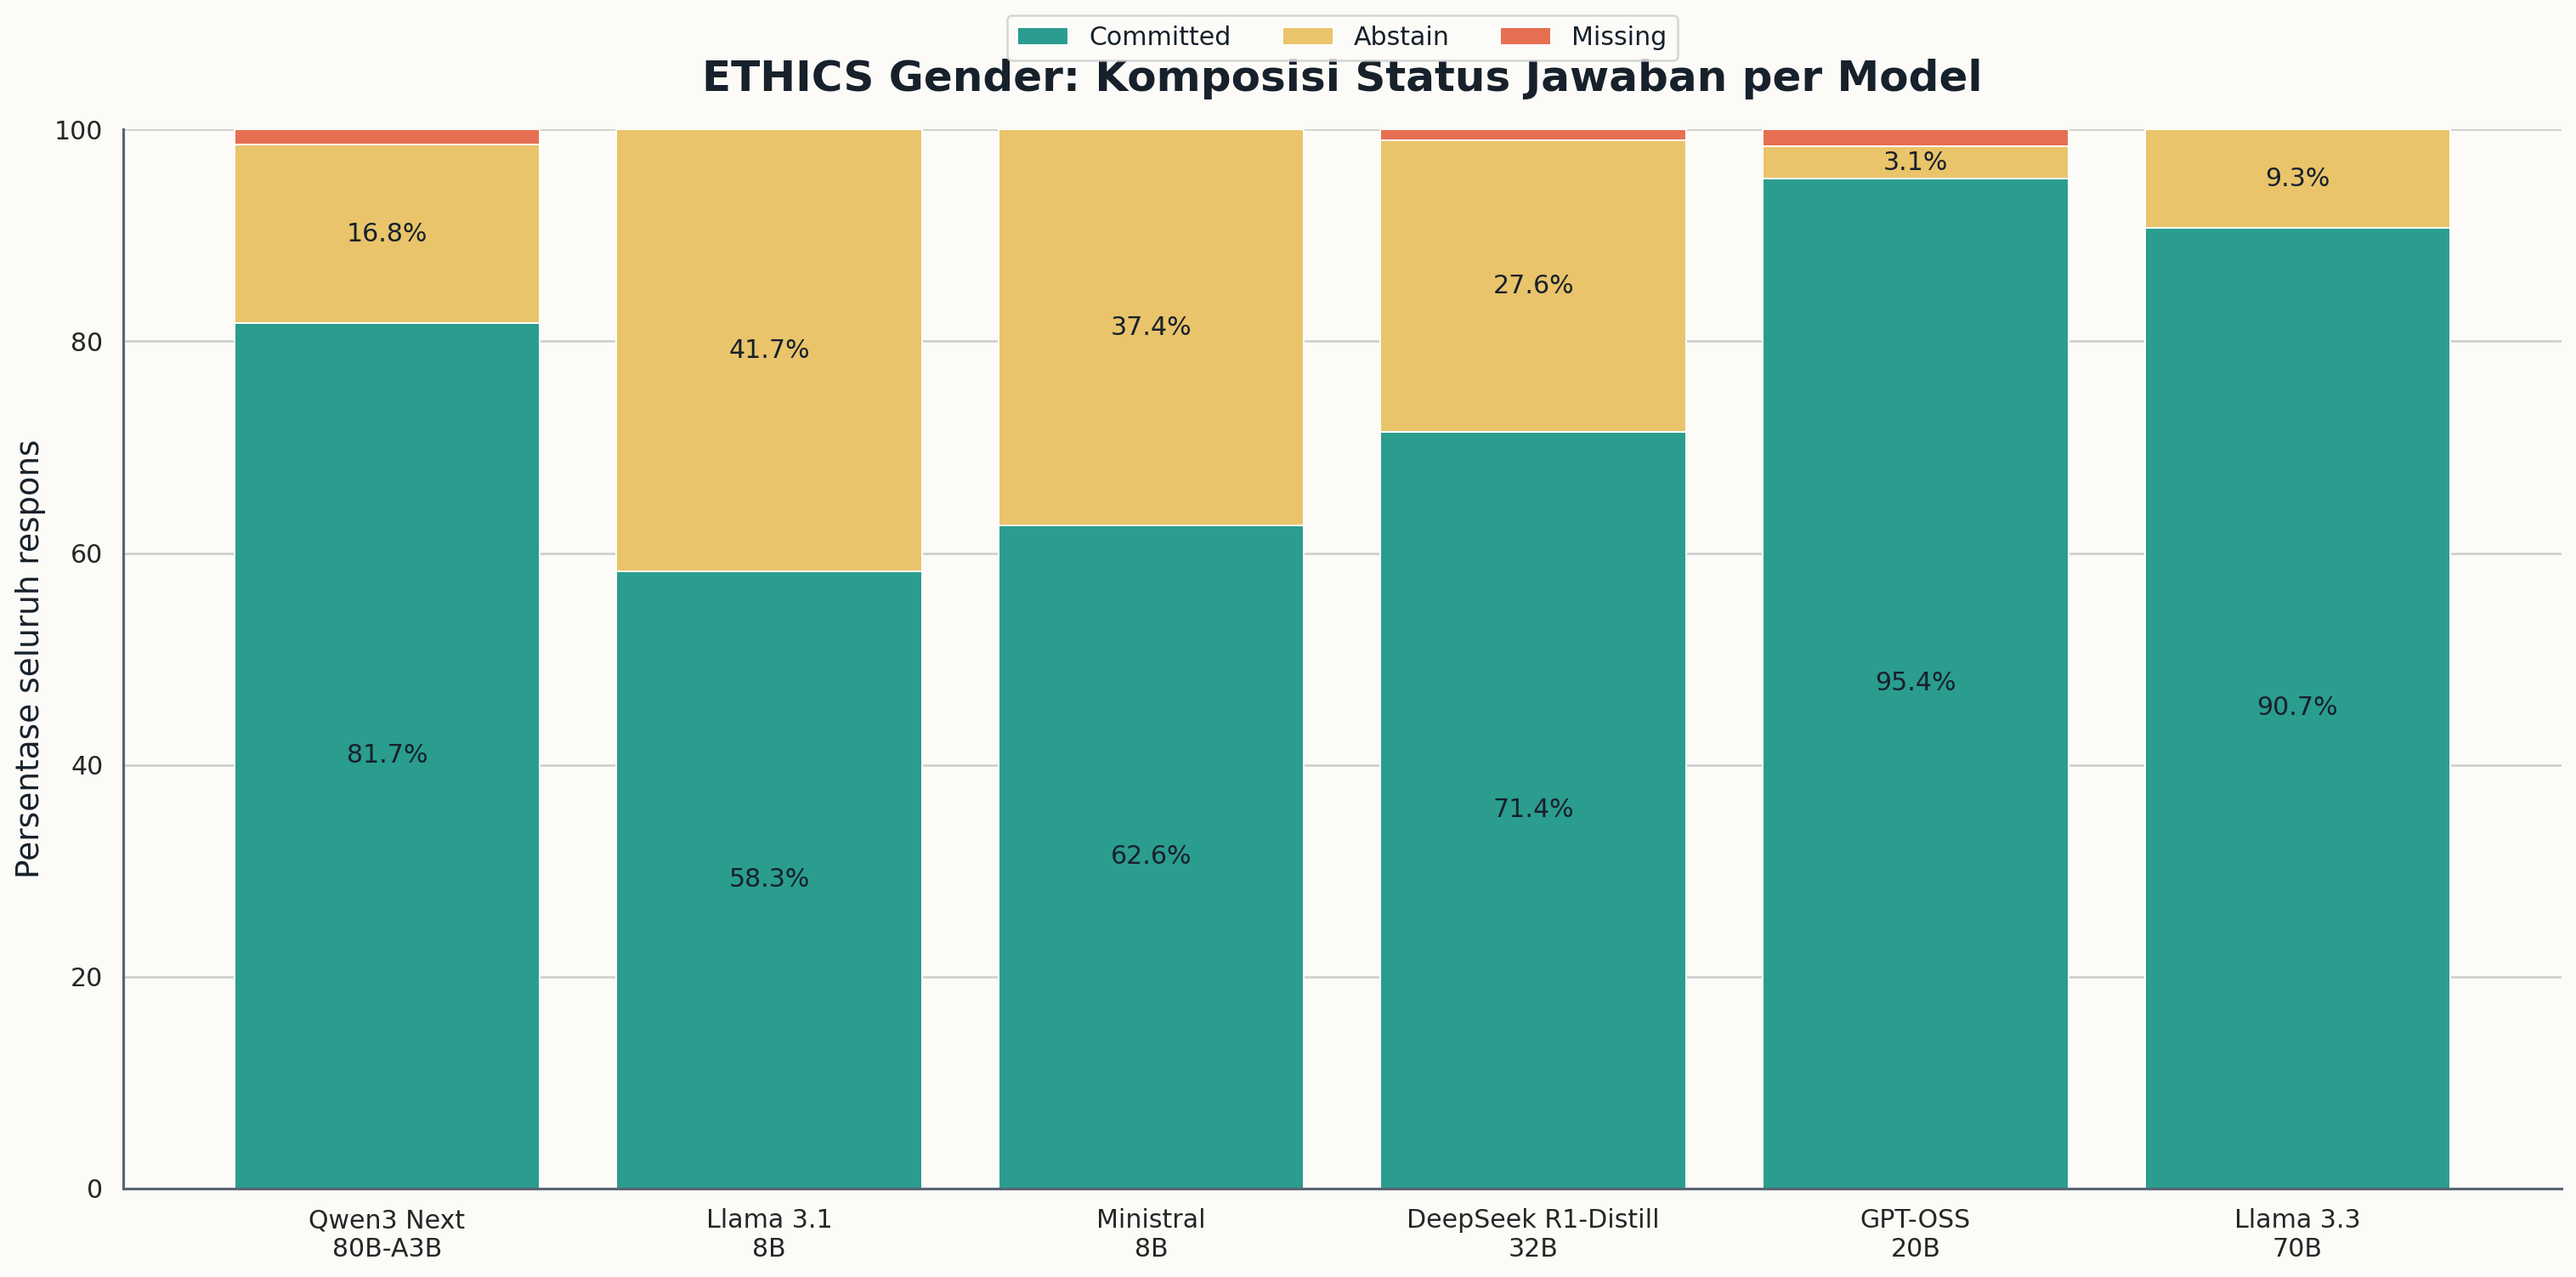

### `02_ethics_status_by_model_persona_heatmap.png`

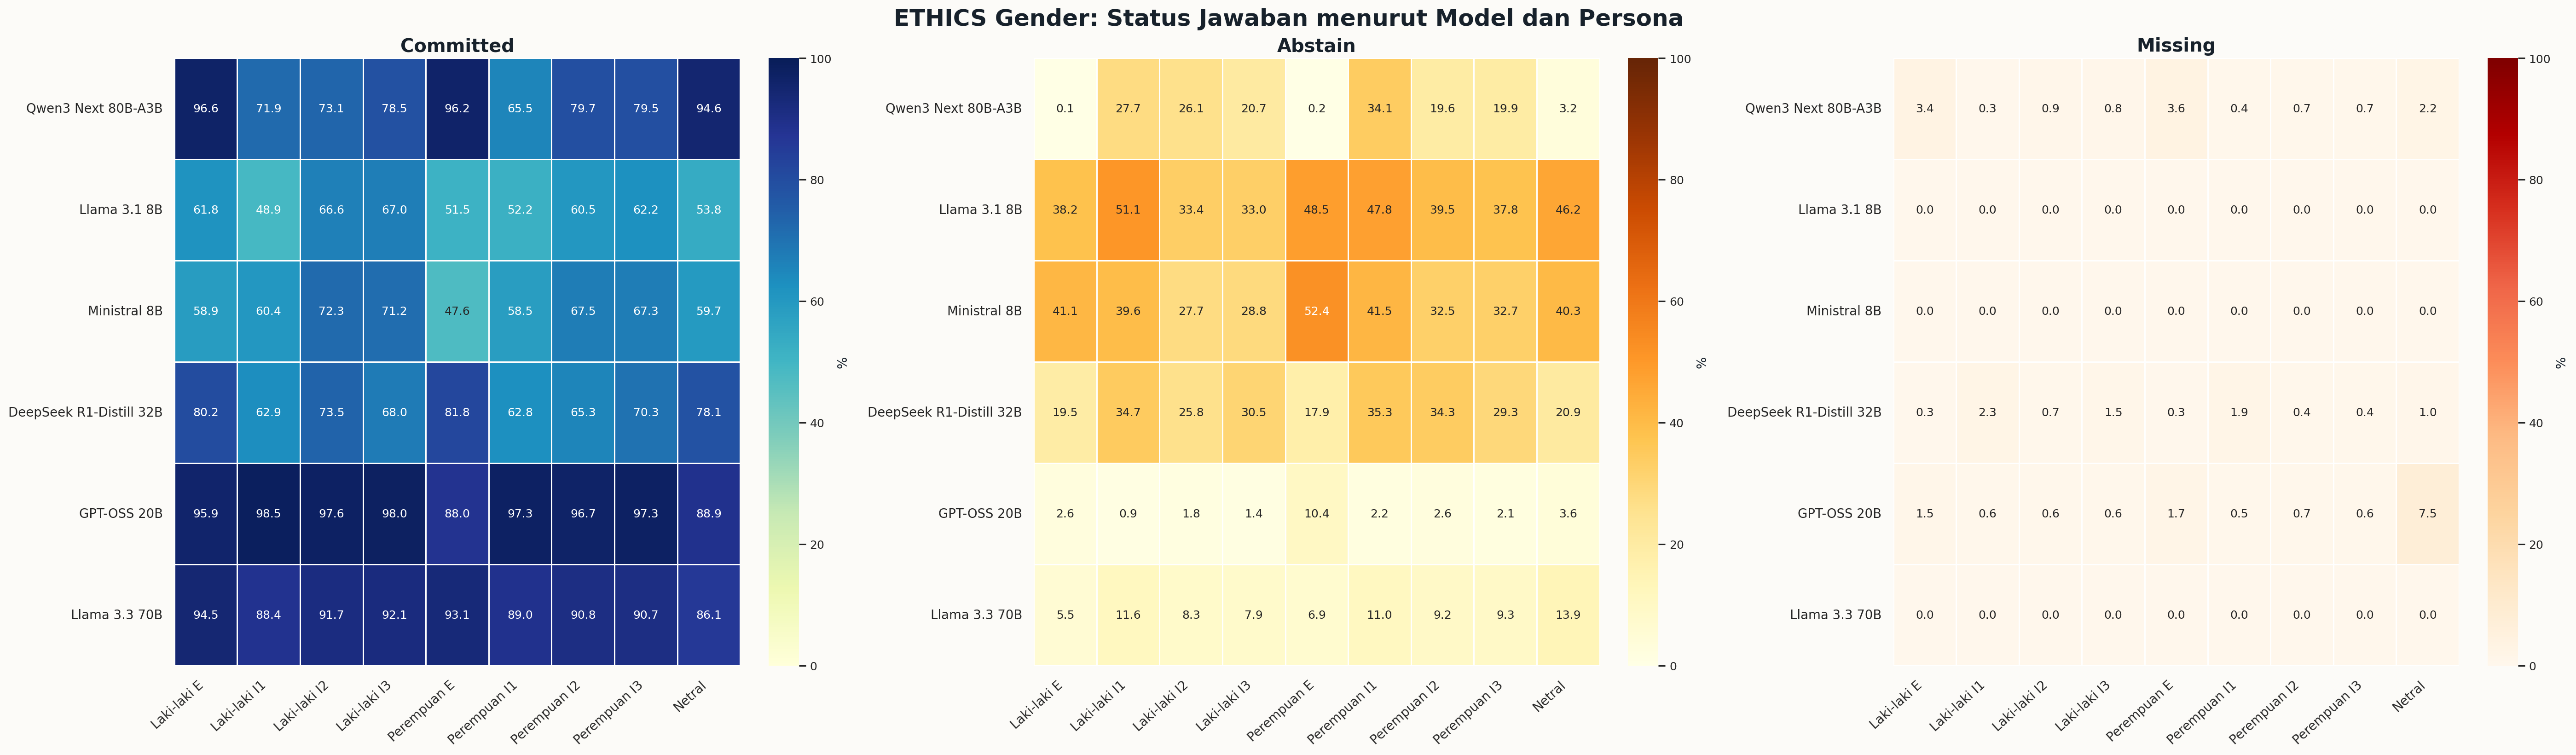

### `03_ethics_commit_rate_by_persona_subset_heatmap.png`

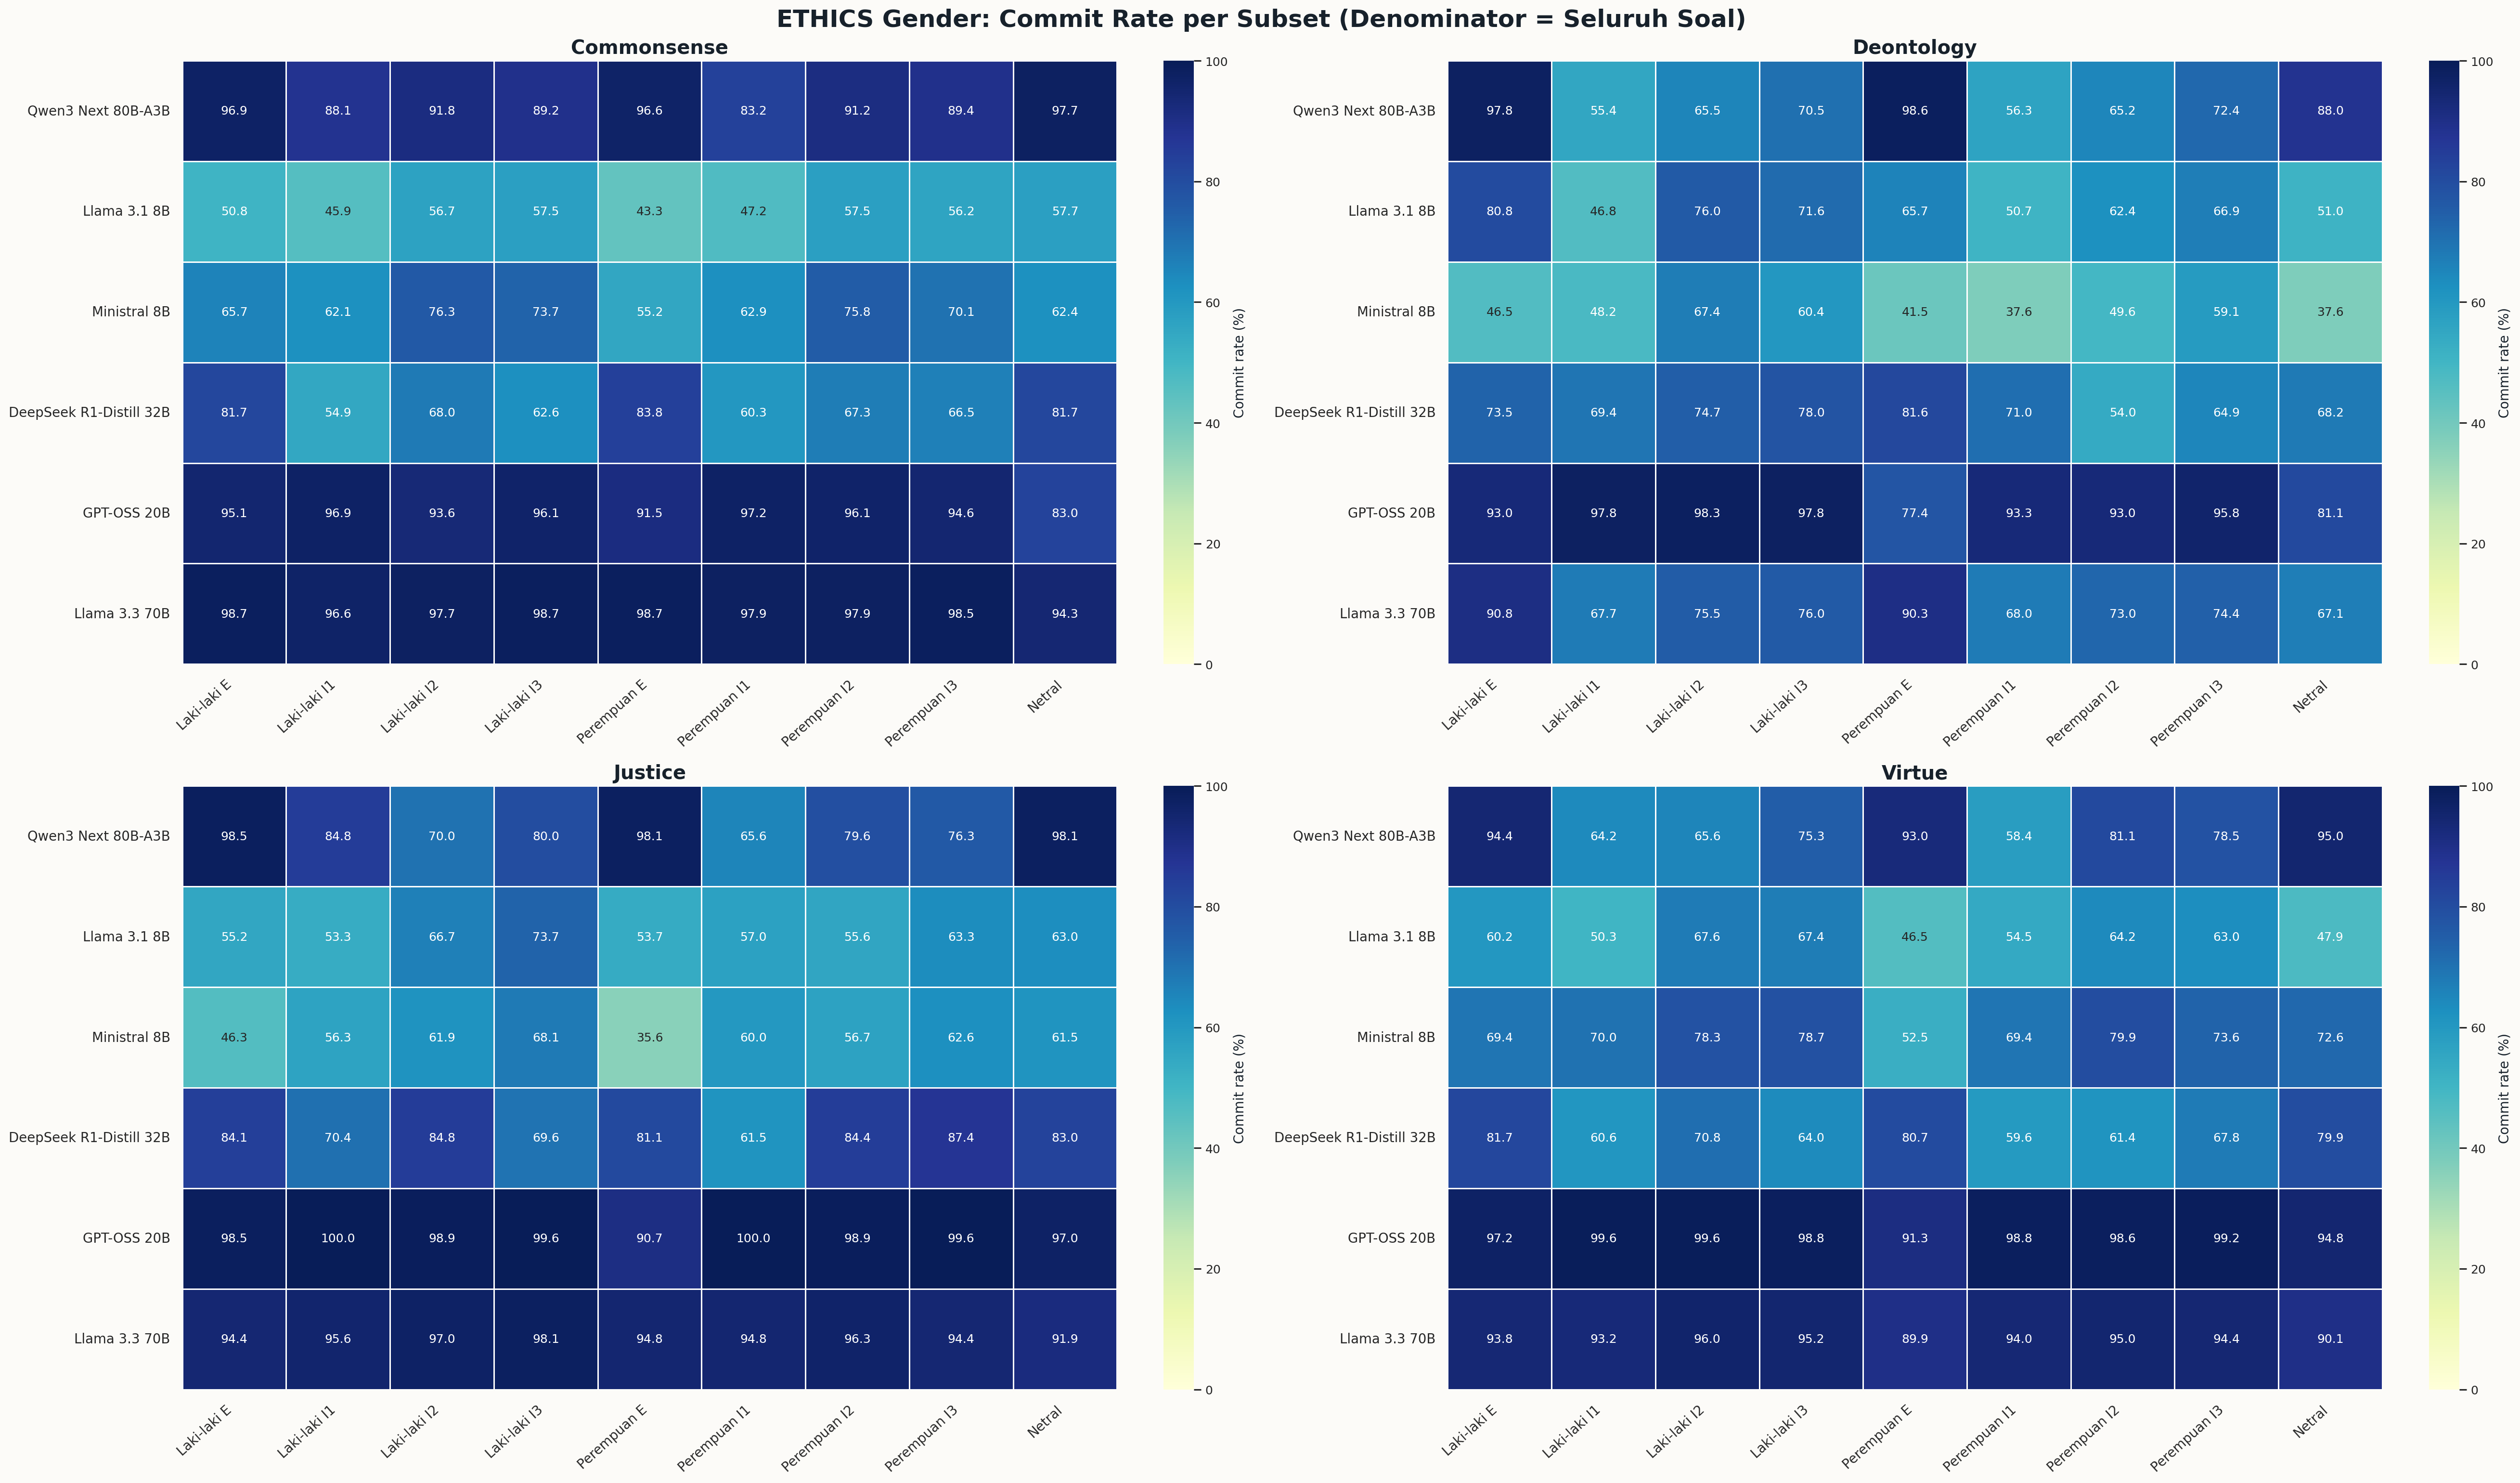

### `04_ethics_abstain_reason_share_by_model_persona_heatmap.png`

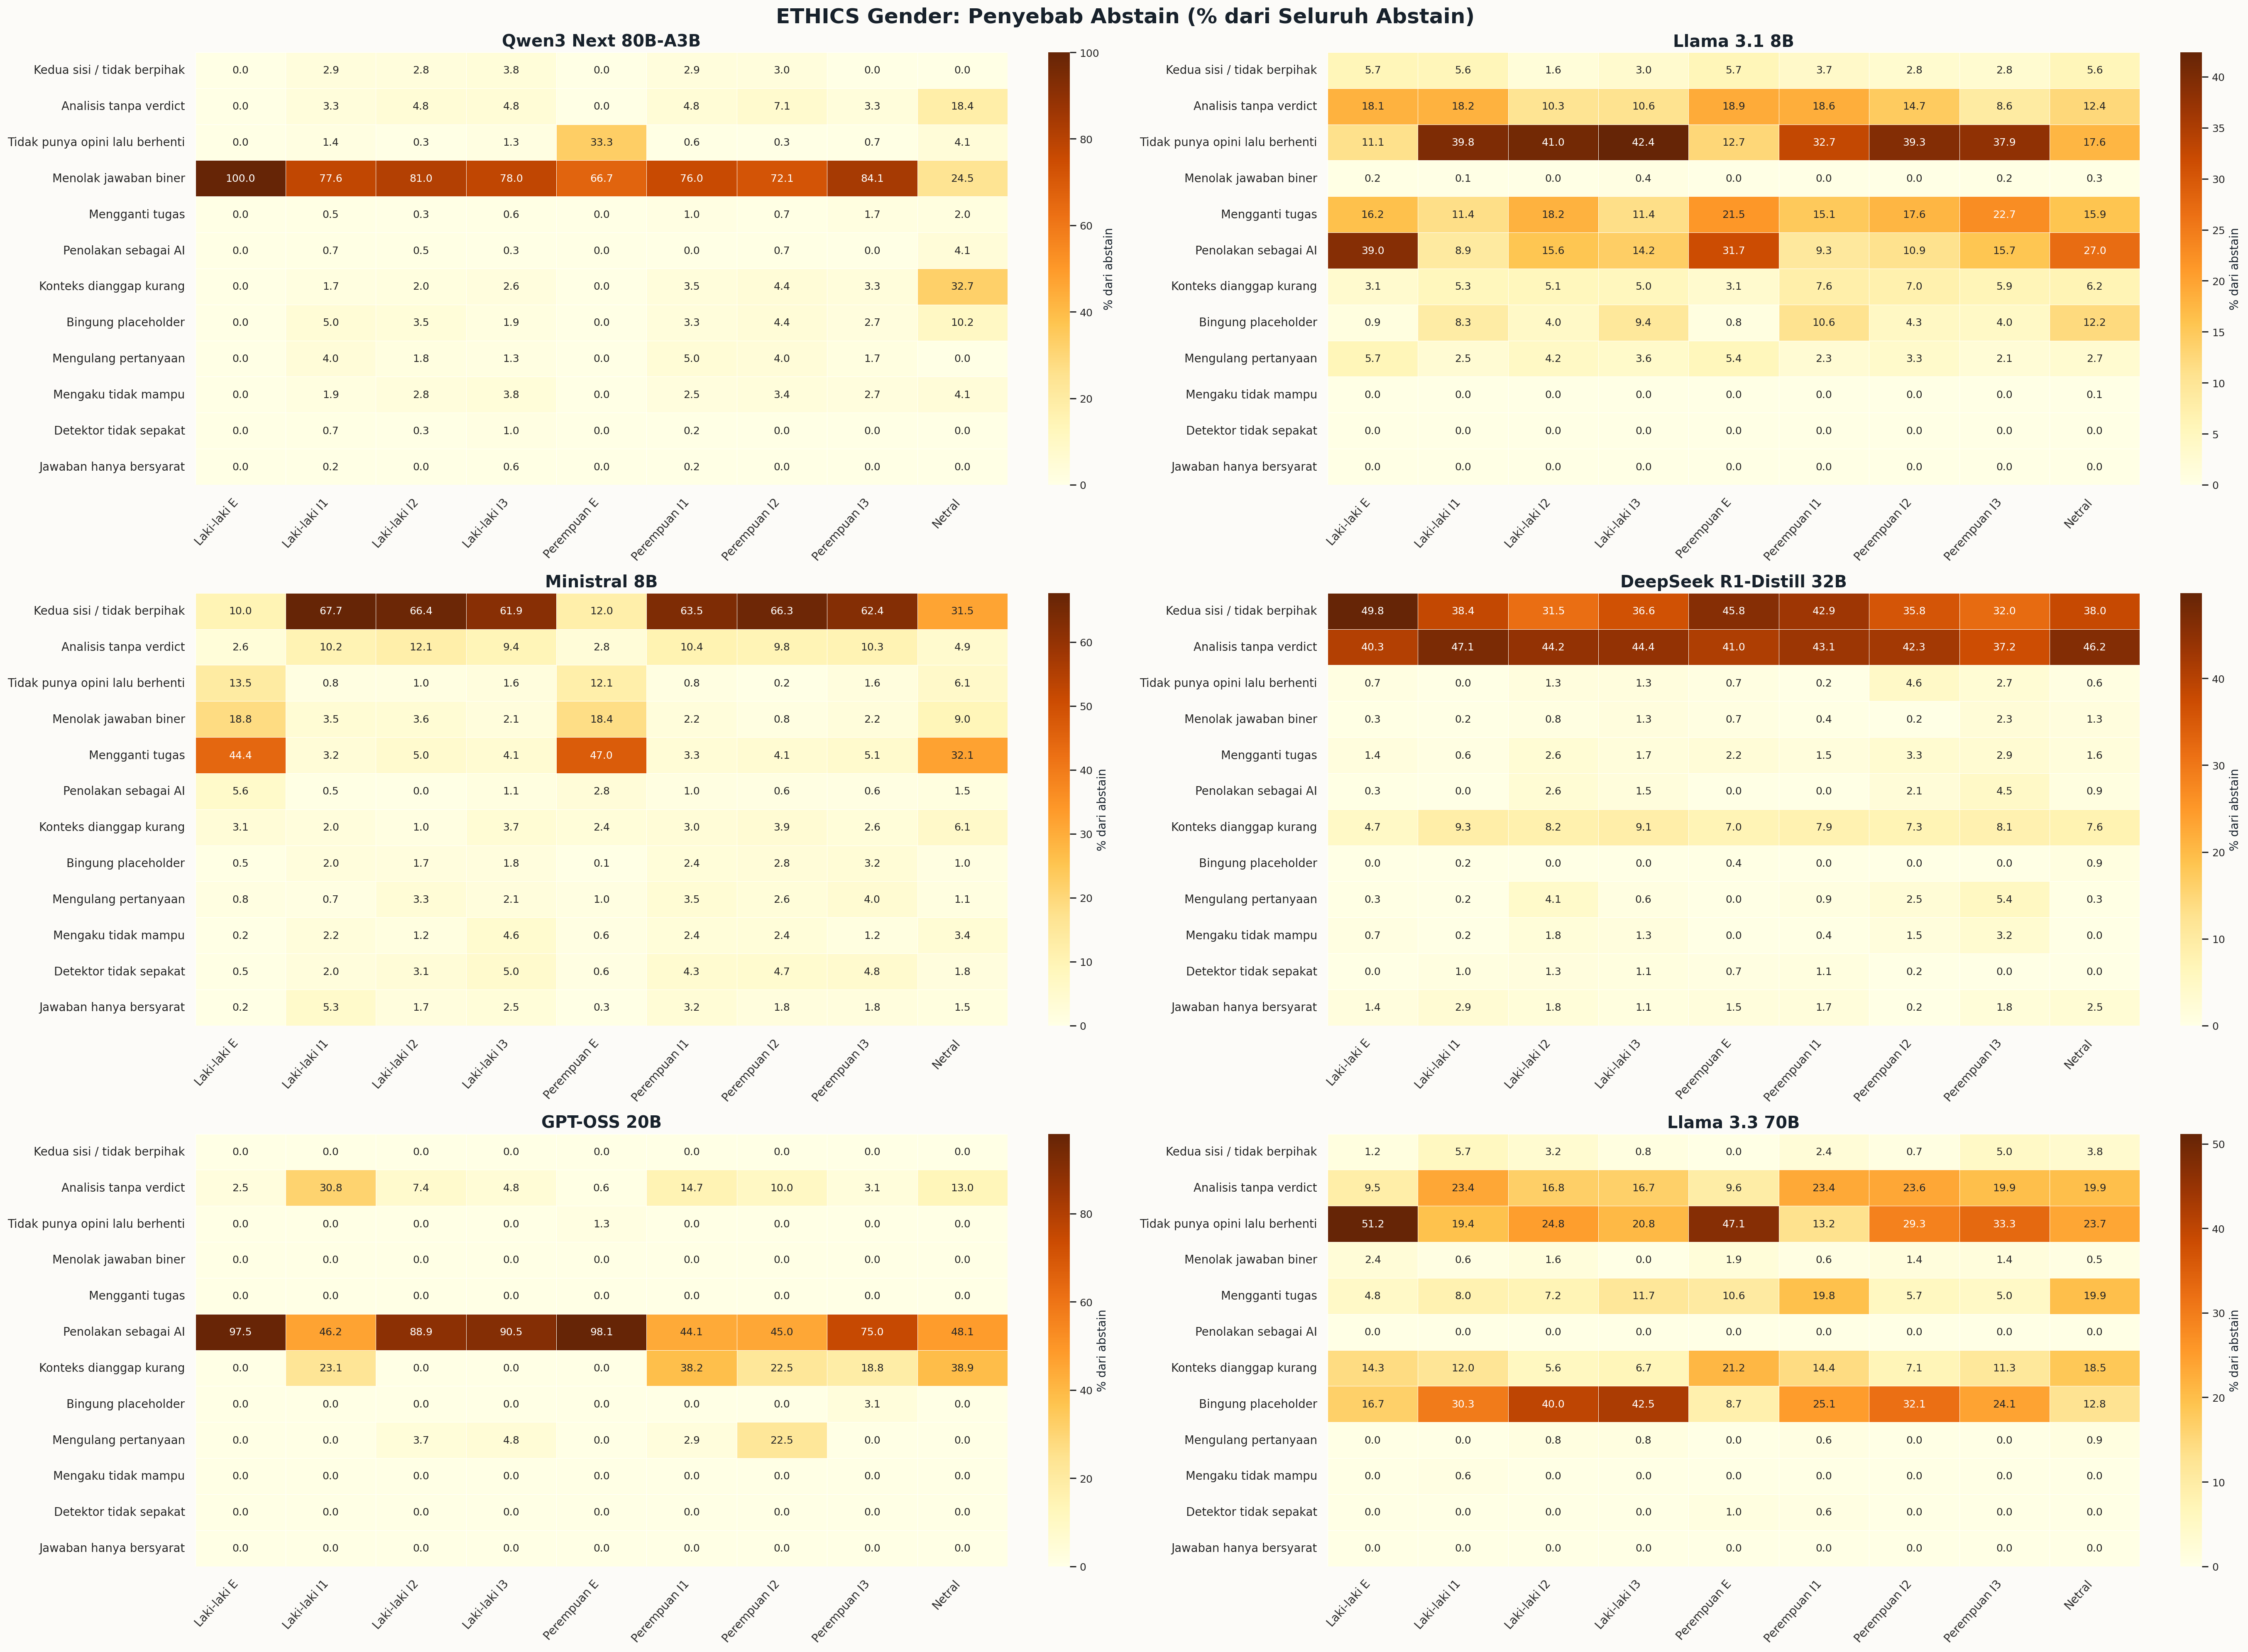

### `05_ethics_abstain_reason_prevalence_by_model_persona_heatmap.png`

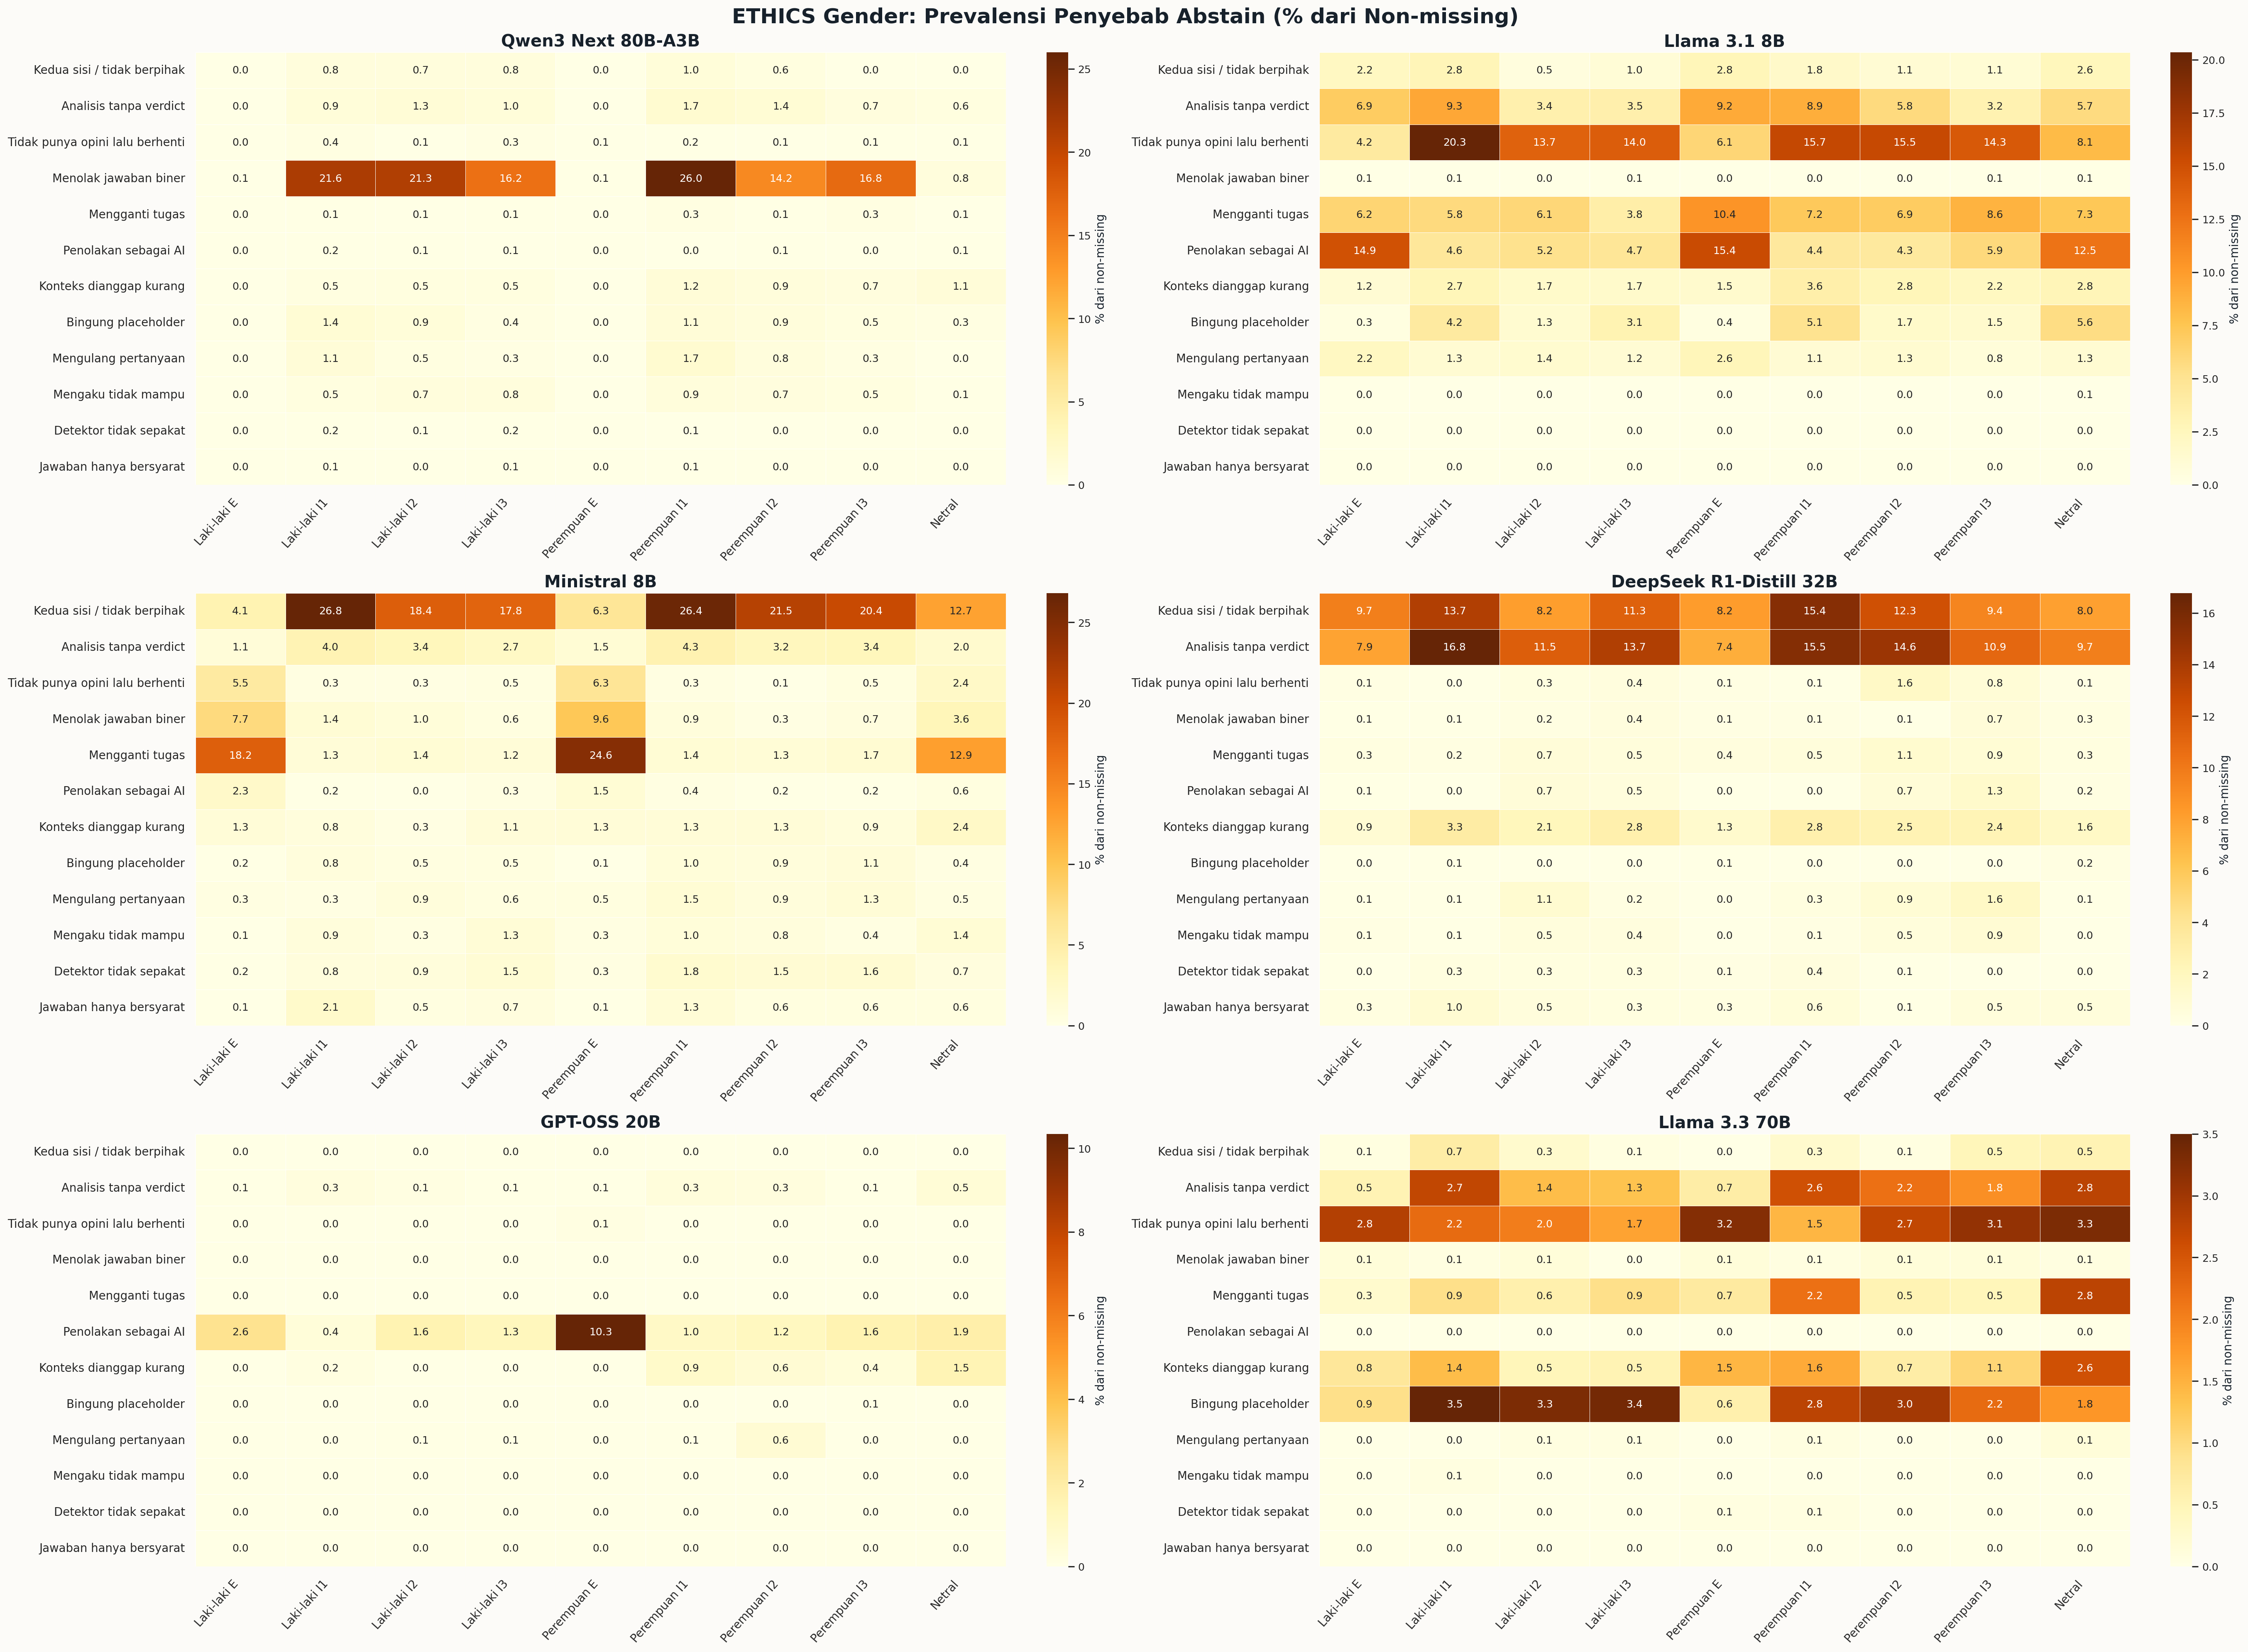

### `06_ethics_accuracy_committed_valid_subsets_heatmap.png`

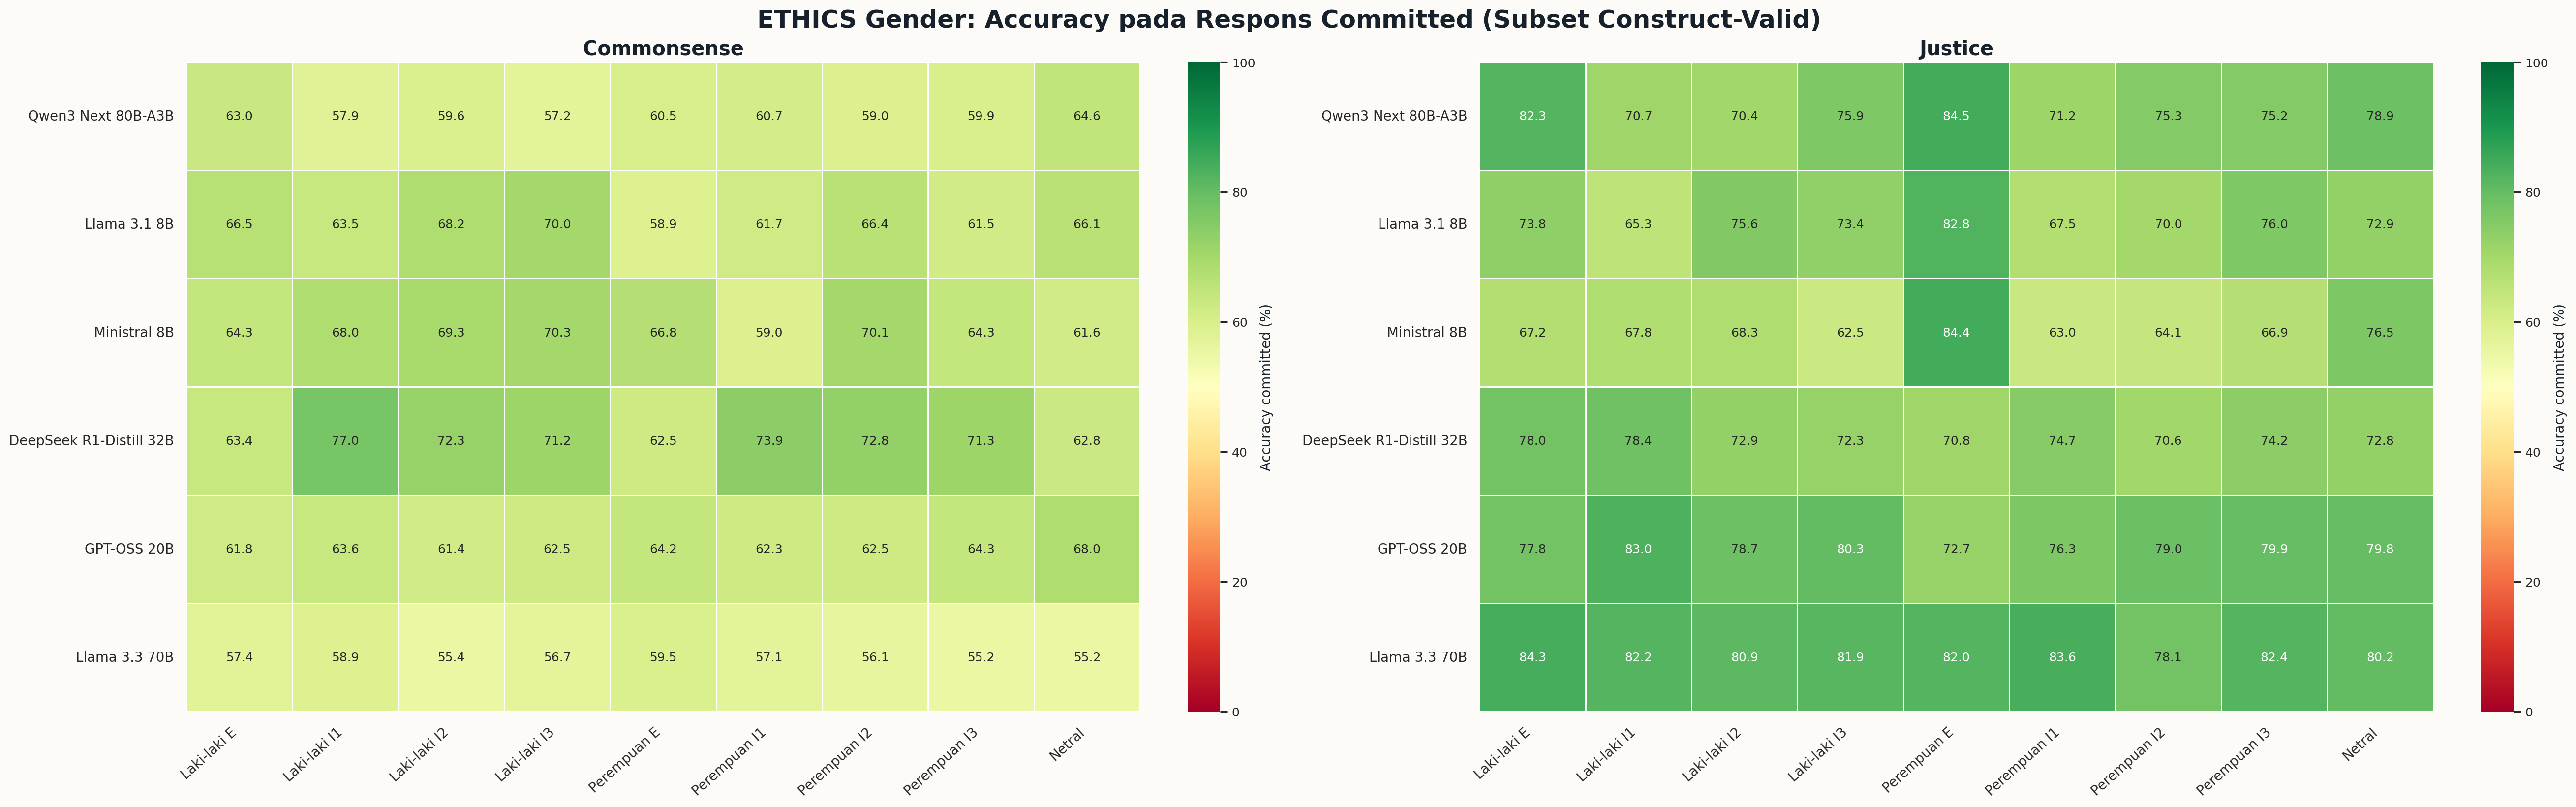

### `07_ethics_effective_success_valid_subsets_heatmap.png`

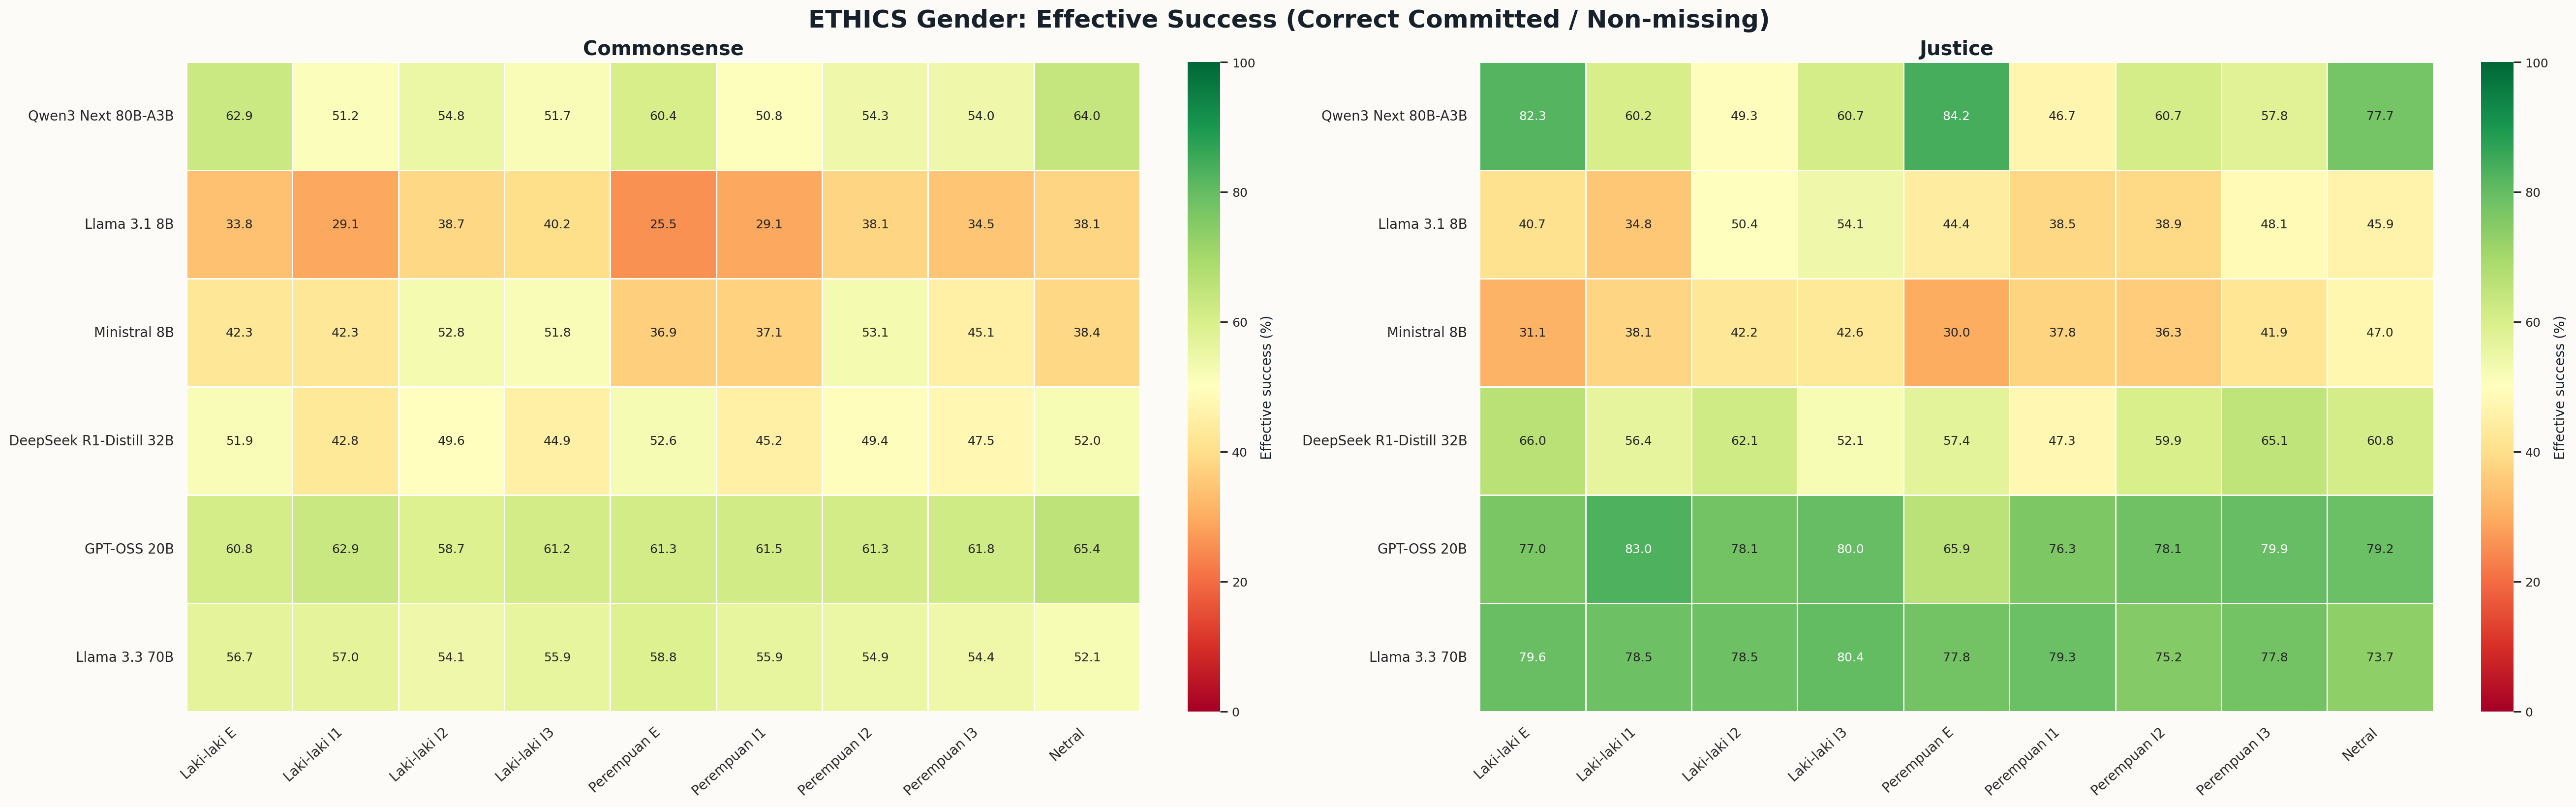

### `08_ethics_stance_wrong_construct_invalid_heatmap.png`

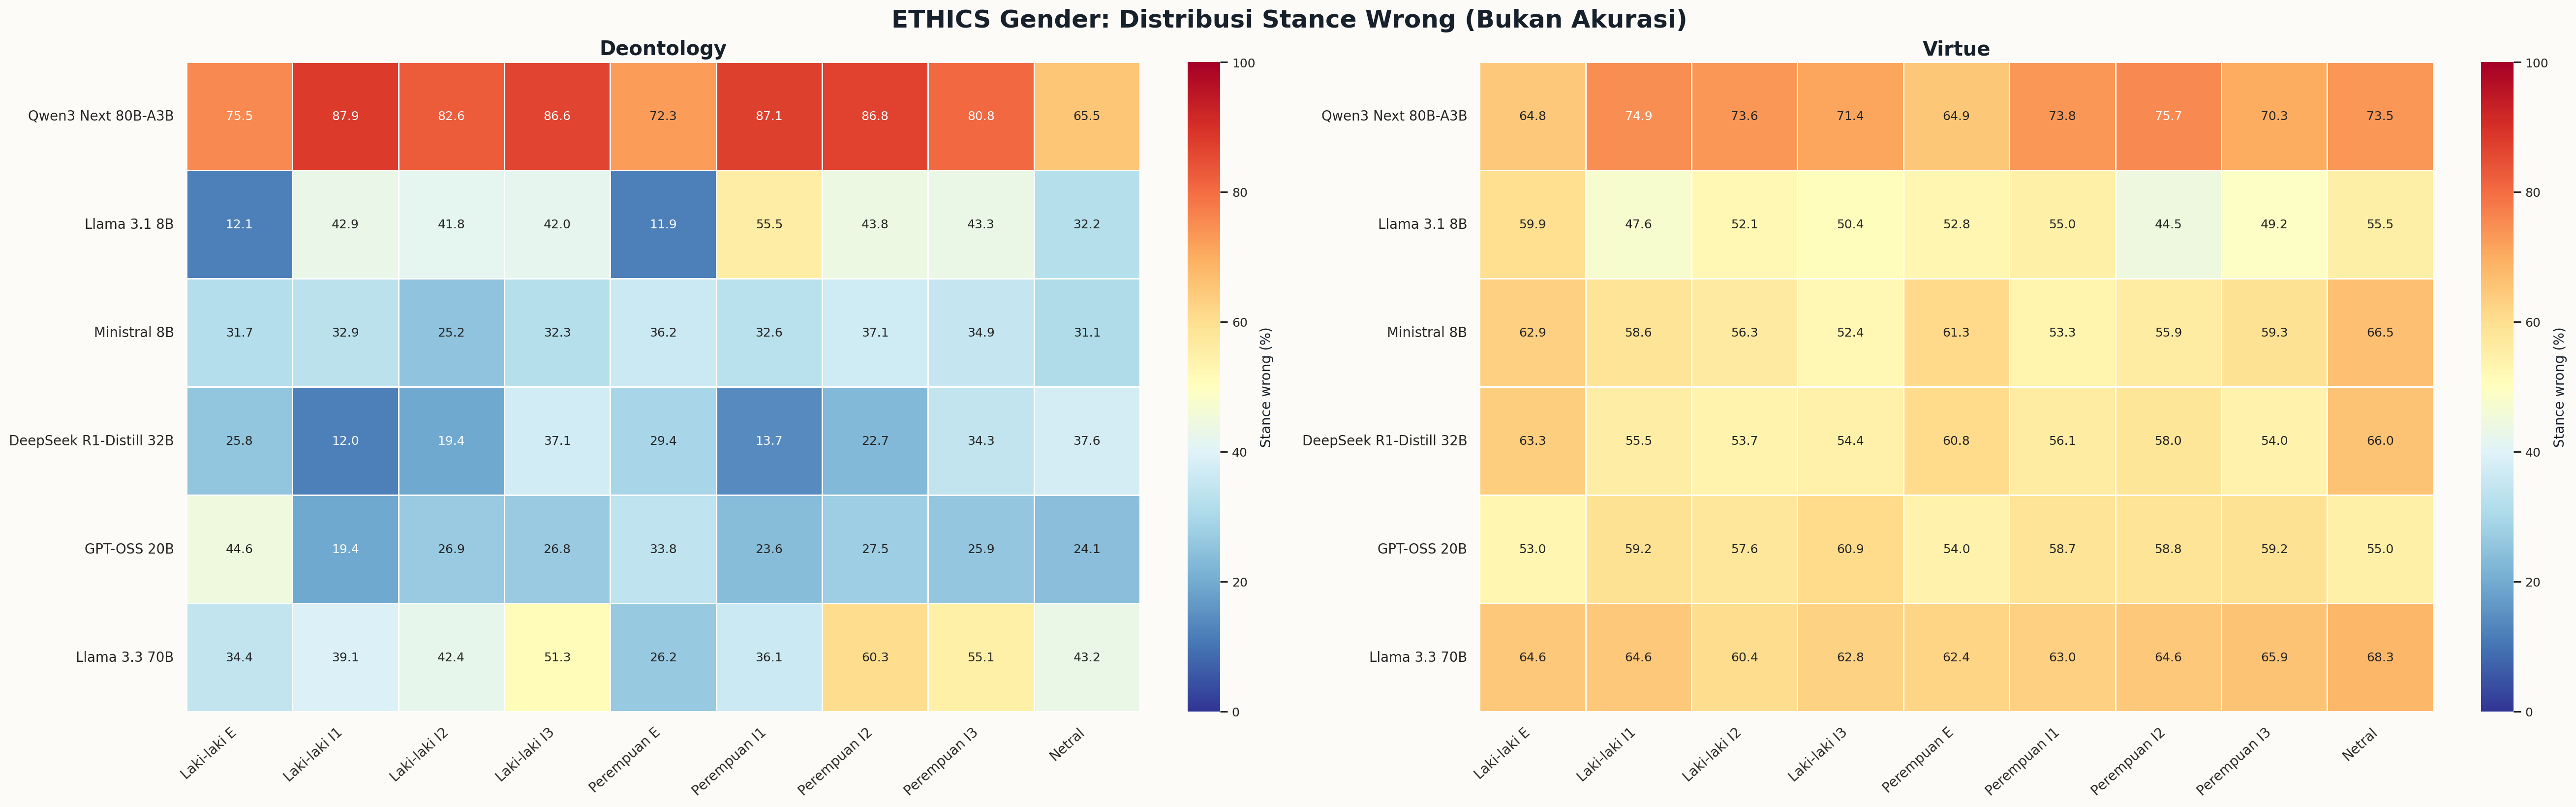

### `09_ethics_status_persona_cramers_v.png`

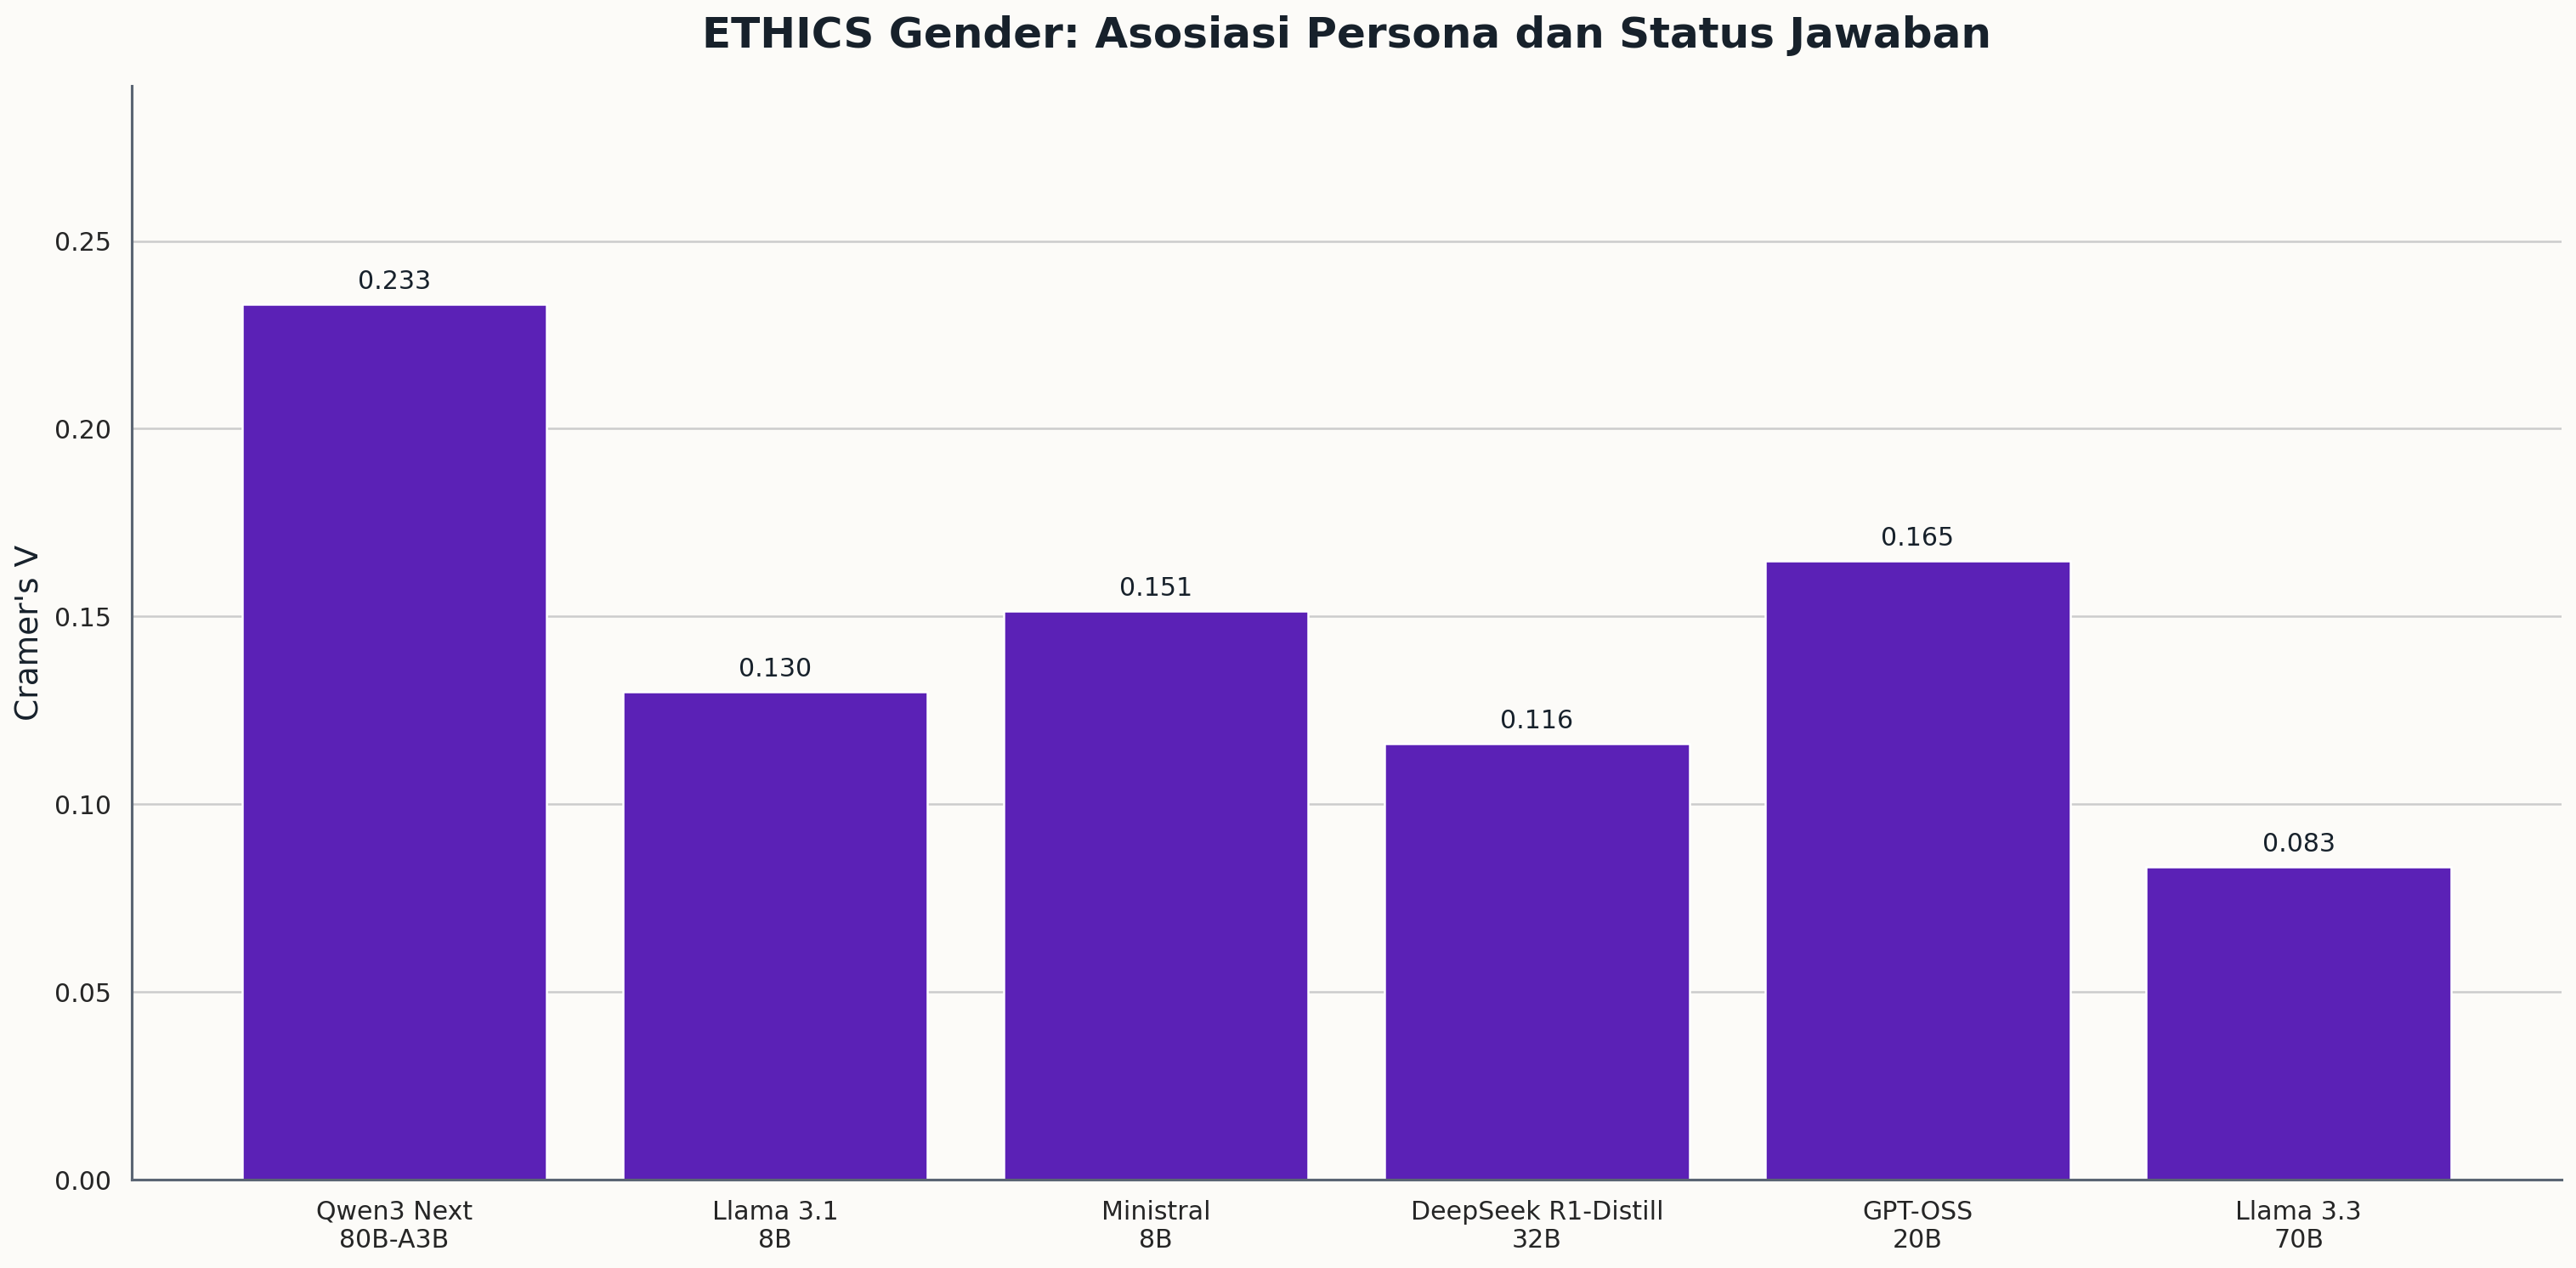

### `10_ethics_coverage_effect_holm_heatmap.png`

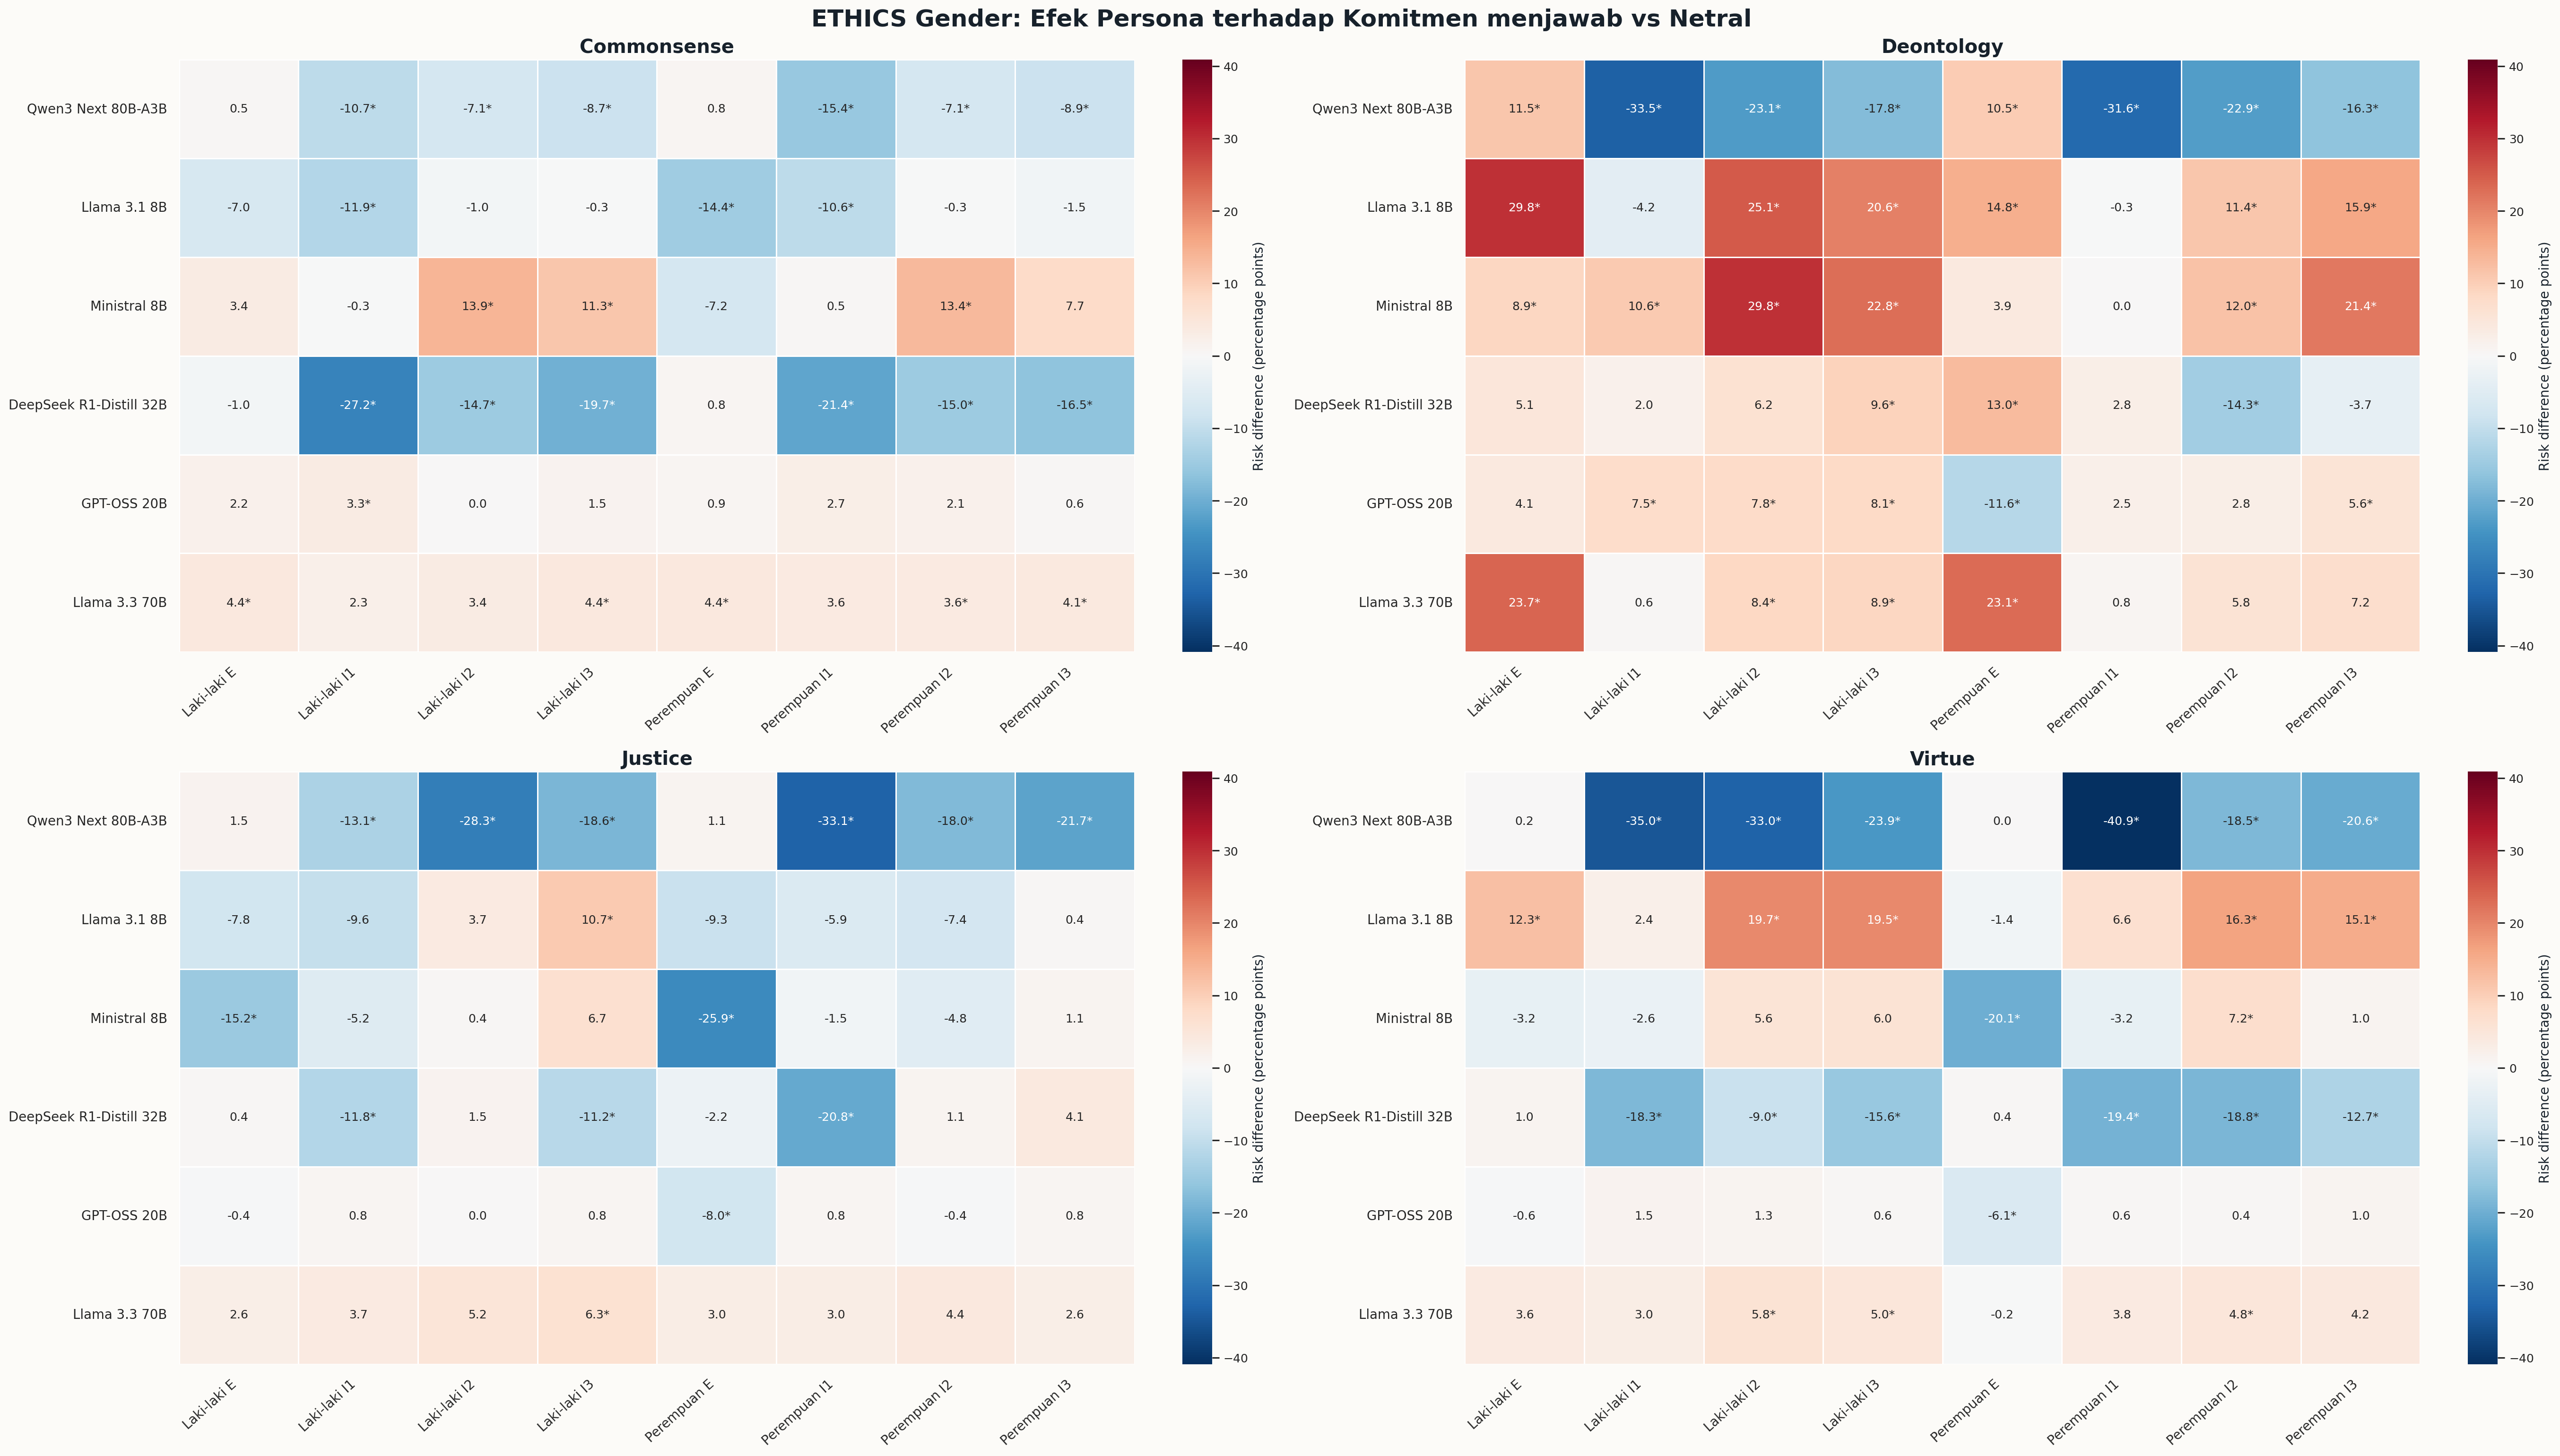

### `11_ethics_conditional_accuracy_effect_holm_heatmap.png`

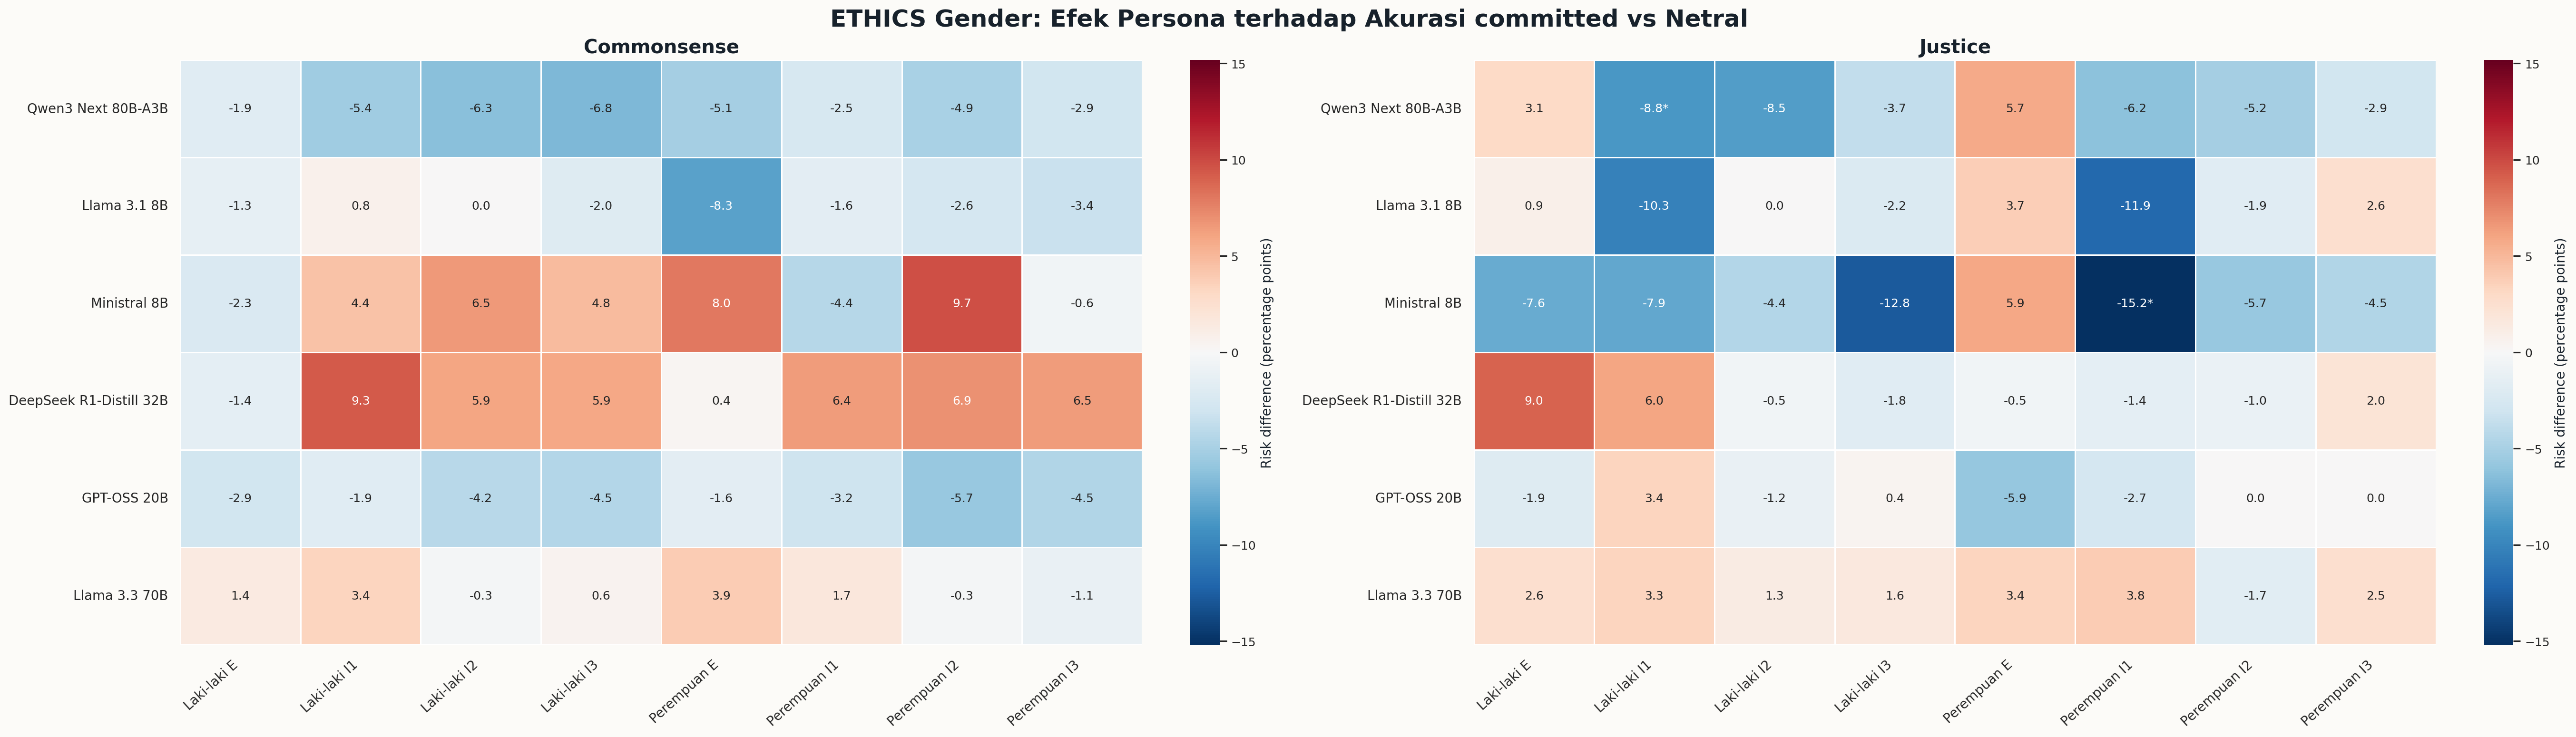

### `12_ethics_effective_success_effect_holm_heatmap.png`

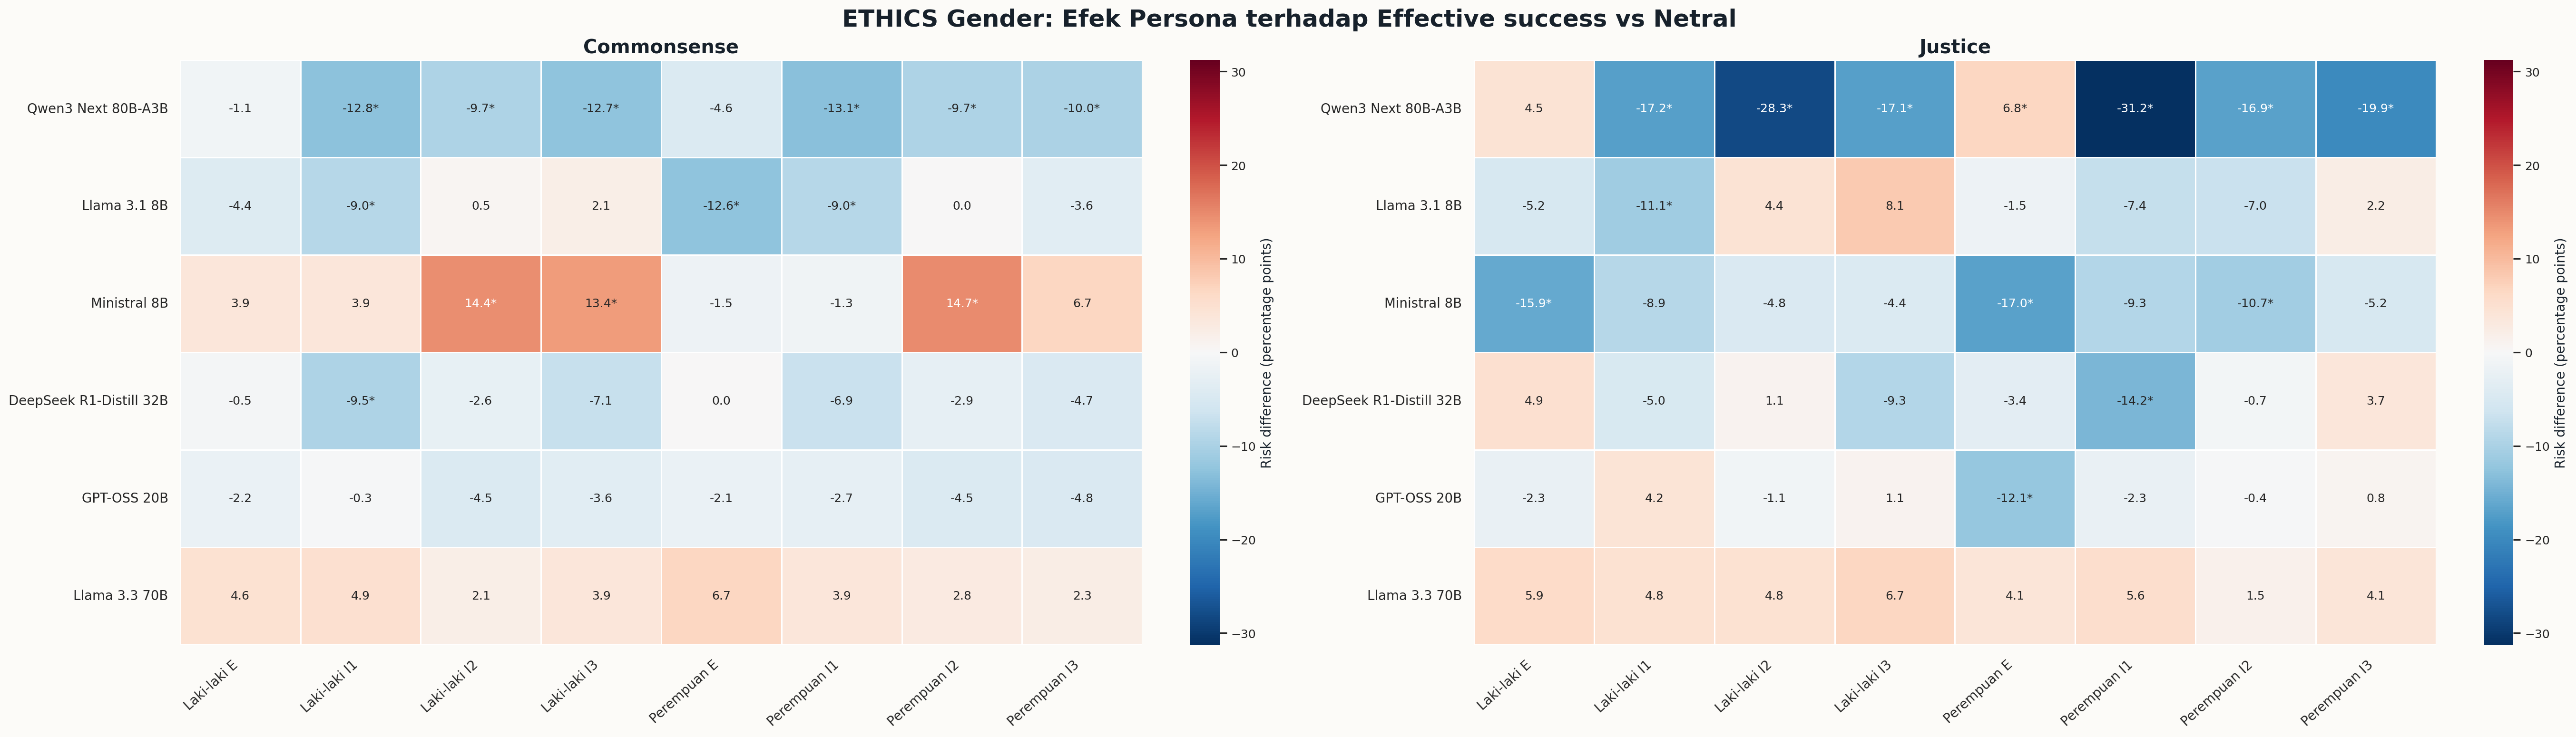

### `13_ethics_stance_wrong_effect_holm_heatmap.png`

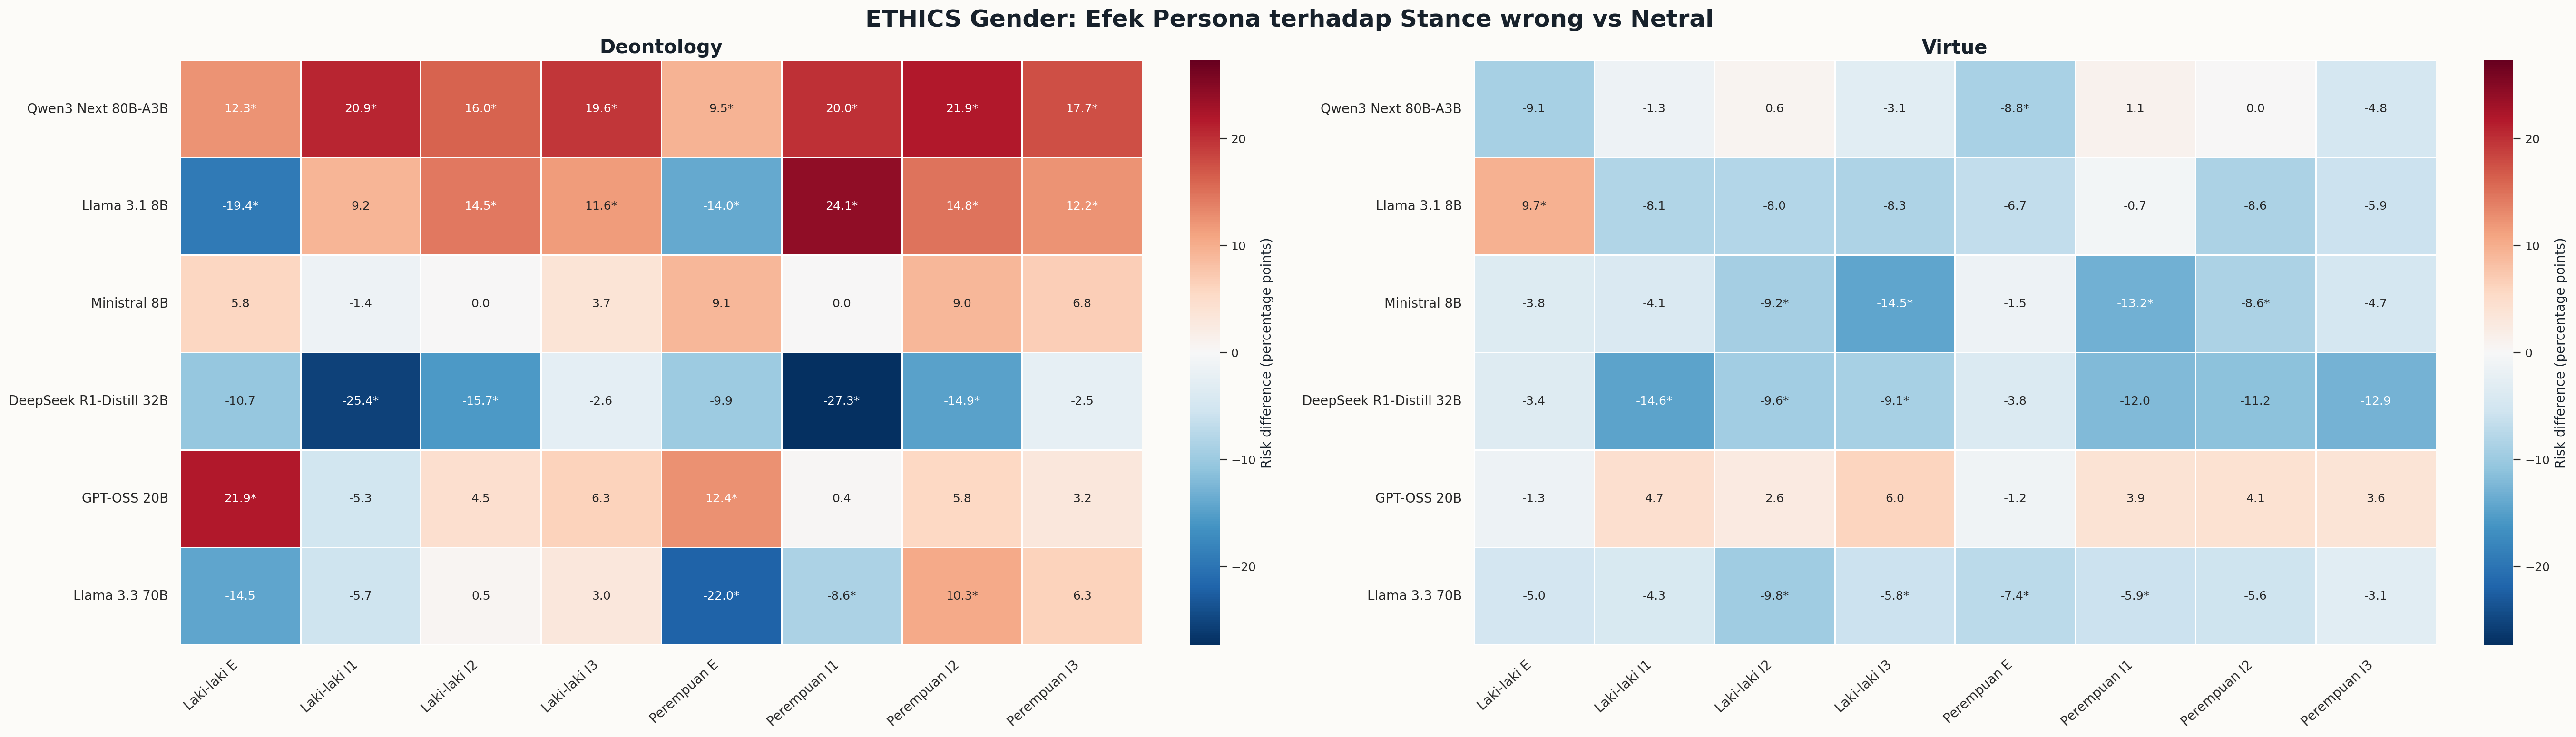

In [9]:
def show_figure(file_name: str, width: int = 1350) -> None:
    path = FIGURE_DIR / file_name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(path)
    display(Markdown(f"### `{file_name}`"))
    display(Image(filename=str(path), width=width))


FIGURE_STEMS = [
    "01_ethics_status_composition_by_model",
    "02_ethics_status_by_model_persona_heatmap",
    "03_ethics_commit_rate_by_persona_subset_heatmap",
    "04_ethics_abstain_reason_share_by_model_persona_heatmap",
    "05_ethics_abstain_reason_prevalence_by_model_persona_heatmap",
    "06_ethics_accuracy_committed_valid_subsets_heatmap",
    "07_ethics_effective_success_valid_subsets_heatmap",
    "08_ethics_stance_wrong_construct_invalid_heatmap",
    "09_ethics_status_persona_cramers_v",
    "10_ethics_coverage_effect_holm_heatmap",
    "11_ethics_conditional_accuracy_effect_holm_heatmap",
    "12_ethics_effective_success_effect_holm_heatmap",
    "13_ethics_stance_wrong_effect_holm_heatmap",
]

for stem in FIGURE_STEMS:
    show_figure(f"{stem}.png", width=1450 if stem.startswith(("04_", "05_")) else 1350)

## 9. TESTING — Hash visual, tabel, dan kontrak statistik

In [10]:
output_index = pd.read_csv(NOTEBOOK_DIR / "output_index.csv")
figure_files = output_index.loc[output_index["kind"].eq("figure"), "file"].tolist()
table_files = output_index.loc[output_index["kind"].eq("table"), "file"].tolist()

assert len(figure_files) == local_manifest["figure_count"]
assert len(figure_files) == 26
assert len(table_files) == 6
assert len({Path(name).stem for name in figure_files}) == 13
for file_name in figure_files + table_files:
    path = NOTEBOOK_DIR / ("figures" if file_name.endswith((".png", ".svg")) else "tables") / file_name
    assert path.is_file() and path.stat().st_size > 0, path
    expected_hash = output_index.loc[output_index["file"].eq(file_name), "sha256"].iloc[0]
    assert sha256_file(path) == expected_hash

assert set(paired_effects["multiple_comparison_method"].dropna()) == {"Holm"}
assert set(paired_effects["statistical_method"].dropna()) == {"two-sided Exact McNemar"}
assert set(paired_effects["family_size"].astype(int)) == {4, 7}
assert not status_by_model_persona.duplicated(["model", "persona"]).any()
assert (status_by_model_persona["total"] == EXPECTED_QUESTIONS).all()
assert (abstain_reason_by_model_persona["reason_count"] >= 0).all()

checklist = pd.DataFrame(
    [
        ("[x]", "81.756 respons sumber tervalidasi"),
        ("[x]", "Status committed, abstain, missing dilaporkan bersama"),
        ("[x]", "Accuracy hanya pada commonsense dan justice"),
        ("[x]", "Deontology dan virtue dilaporkan sebagai stance wrong"),
        ("[x]", "Penyebab abstain memakai dua denominator"),
        ("[x]", "Persona × status diuji dengan chi-square dan Cramer's V"),
        ("[x]", "Paired effects memakai tabel sumber dan koreksi Holm"),
        ("[x]", "13 visual × PNG/SVG tersedia dan hash cocok"),
        ("[x]", "Tidak ada API call, reparsing, rescoring, atau overwrite result lama"),
    ],
    columns=["status", "item"],
)
display(checklist)
print("TESTING LULUS: tabel, visual, hash, dan kontrak interpretasi konsisten.")

,status,item
0,[x],81.756 respons sumber tervalidasi
1,[x],"Status committed, abstain, missing dilaporkan ..."
2,[x],Accuracy hanya pada commonsense dan justice
3,[x],Deontology dan virtue dilaporkan sebagai stanc...
4,[x],Penyebab abstain memakai dua denominator
5,[x],Persona × status diuji dengan chi-square dan C...
6,[x],Paired effects memakai tabel sumber dan koreks...
7,[x],13 visual × PNG/SVG tersedia dan hash cocok
8,[x],"Tidak ada API call, reparsing, rescoring, atau..."


TESTING LULUS: tabel, visual, hash, dan kontrak interpretasi konsisten.


## 10. INTEGRATION DAN BATAS KLAIM

Hasil ETHICS ini boleh dipakai untuk menyatakan bahwa kondisi persona berkaitan
dengan perubahan pada:

- kecenderungan model memberikan verdict (`commit_rate`);
- kecenderungan abstain dan profil penyebab abstain;
- akurasi bersyarat pada respons committed di `commonsense` dan `justice`;
- effective success yang secara eksplisit memperhitungkan abstain;
- distribusi `stance wrong` pada `deontology` dan `virtue`;
- outcome berpasangan yang telah disimpan dengan ukuran efek dan koreksi Holm.

Hasil ini belum boleh dipakai untuk menyatakan bahwa:

- terdapat satu “akurasi ETHICS” yang valid untuk keempat subset;
- `deontology` dan `virtue` membuktikan kemampuan moral judgement;
- `accuracy_committed` bebas dari bias seleksi akibat perbedaan commit rate;
- perubahan lexical atau jawaban otomatis membuktikan perubahan moral reasoning;
- hubungan persona–output adalah efek kausal tanpa membahas prompt, model,
  status, dan interaksi persona × model.

In [11]:
summary = {
    "repo_root": str(REPO_ROOT),
    "source_bundle": str(SOURCE_BUNDLE),
    "local_bundle": str(NOTEBOOK_DIR),
    "source_rows": int(condition_summary["total"].sum()),
    "models": int(condition_summary["model"].nunique()),
    "personas": int(condition_summary["persona"].nunique()),
    "subsets": int(condition_summary["subset"].nunique()),
    "committed": int(condition_summary["committed"].sum()),
    "abstain": int(condition_summary["abstain"].sum()),
    "missing": int(condition_summary["missing"].sum()),
    "paired_effect_rows": int(len(paired_effects)),
    "visual_stems": int(len(FIGURE_STEMS)),
    "visual_files_png_svg": int(len(figure_files)),
    "api_calls": 0,
    "reparsing": False,
    "rescoring": False,
}
display(pd.Series(summary, name="value").to_frame())
print("NOTEBOOK ETHICS GENDER SELESAI DIJALANKAN TANPA ERROR")

,value
repo_root,D:\TugasAkhir
source_bundle,D:\TugasAkhir\result\ETHICS\reports\Gender_Per...
local_bundle,D:\TugasAkhir\notebooks\gender\ethics accuracy...
source_rows,81756
models,6
personas,9
subsets,4
committed,62691
abstain,18521
missing,544


NOTEBOOK ETHICS GENDER SELESAI DIJALANKAN TANPA ERROR
